### Partea 2

- Antrenarea modelelor shallow (Linear Regression, Random Forest , kNN, SVM)
- Vom extrage features din fisierele finale rezultate din EDA , apoi extrag un top 20, top 40 (deci nu folosesc shared csvs)
- de asemenea vom aplica in faza de preprocesare : StandardScaler() pe toate atributele

In [75]:
#%pip install lexicalrichness
#%pip install pyphen
%pip install stopwordsiso

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from lexicalrichness import LexicalRichness
import unicodedata

import pyphen
import re
from collections import Counter
import stopwordsiso as stopwords
from sklearn.svm import LinearSVC

import spacy

In [2]:
stopwords.has_lang("ro")

True

In [3]:

STOPWORDS_RO = stopwords.stopwords("ro")
print(STOPWORDS_RO)

{'acela', 'cînd', 'avem', 'voi', 'oricare', 'inapoi', 'si', 'astazi', 'noua', 'ceea', 'dinaintea', 'deasupra', 'său', 'sa-ti', 'unora', 'uneori', 'astăzi', 'cite', 'cind', 'alte', 'ia', 'multă', 'acele', 'prin', 'dată', 'ăsta', 'atare', 'unu', 'spate', 'un', 'nou', 't', 'tale', 'vi', 'atata', 'avut', 'contra', 'dupa', 'multi', 'au', 'aţi', 'despre', 'drept', 'ni', 'altii', 'două', 'întrucât', 'peste', 'plus', 'totuşi', 'sintem', 'doilea', 'aceşti', 'dat', 'câţi', 'nişte', 'aveţi', 'ce', 'avea', 'cat', 'desi', 'era', 'exact', 'dintr', 'nevoie', 'căror', 'atatia', 'câtva', 'tine', 'careia', 'frumos', 'oricând', 'x', 'ba', 'cand', 'celor', 'ci', 'parca', 'lor', 'mulţumesc', 'ălea', 'zi', 'oricum', 'are', 'tu', 'unul', 'inainte', 'citiva', 'or', 'adica', 'aiurea', 'am', 'unde', 'suntem', 'lîngă', 'zice', 'mai', 'decit', 'mine', 'timp', 'citeva', 'bucur', 'acestei', 'dau', 'mult', 'către', 'imi', 'carora', 'atunci', 'îţi', 'alta', 'că', 'numai', 'nimeni', 'ori', 'voastră', 'sau', 'al', 'ace

In [4]:
full_ro_train_df = pd.read_csv("stylo_text_features/train_romanian_only_stylo_full.csv")
full_ro_val_df = pd.read_csv("stylo_text_features/validation_romanian_only_stylo_full.csv")
full_ro_test_df = pd.read_csv("stylo_text_features/test_romanian_only_stylo_full.csv")

# MOLDOVA
full_mo_train_df = pd.read_csv("stylo_text_features/train_moldavian_only_stylo_full.csv")
full_mo_val_df = pd.read_csv("stylo_text_features/validation_moldavian_only_stylo_full.csv")
full_mo_test_df = pd.read_csv("stylo_text_features/test_moldavian_only_stylo_full.csv")

In [5]:
print(full_mo_train_df.shape)
print(full_mo_test_df.shape)
print(full_mo_val_df.shape)

(60236, 35)
(1195, 35)
(1214, 35)


Normalizare nume autori
- aparent este o probblema de confuzie: Aneta GROSU vs Aneta Grosu si mai sunt cativa asa
- folosim o functie de normalizare
- si iarasi am  Realitatea md in moldova...

In [6]:
def normalize_author(name):
    if not isinstance(name, str):
        return name
    #return name.strip().title()  # "ANETA GROSU" -> "Aneta Grosu"
# ramane totusi problema cu cei care au si nu au diacritice dar sunt la fel (Diana Gatcan asta)
    # mai intai facem literele mici
    name = name.lower().strip()
    # scoatem diacriticele
    # cum functioneaza asta:
    # unicode transforma cu NFD un caracter de exemplu t de la tap in t + <diacritica> 
    # diacritica e tip Mn = Mark + nonspacing (diacritca)
    # NFD normal form decomposed iti scoate chars din text 
    result = ""
    normalized_name = unicodedata.normalize('NFD', name)
    for char in normalized_name:
        if unicodedata.category(char) != 'Mn':
            result =  result + char
    # ok acum bring it back together
    name = " ".join(result.split())
    name = name.title()

    return name

#print(normalize_author('Diana GATCAN'))
# aplici pe toate dataframe-urile
for df in [full_mo_train_df, full_mo_val_df, full_mo_test_df, full_ro_train_df, full_ro_val_df, full_ro_test_df]:
    df['author'] = df['author'].apply(normalize_author)

In [7]:
REDACTII_MO = ['Realitatea Md']  # adaugi variante

for df in [full_mo_train_df, full_mo_val_df, full_mo_test_df]:
    df.drop(df[df['author'].isin(REDACTII_MO)].index, inplace=True)

print(full_mo_train_df.shape)
print(full_mo_test_df.shape)
print(full_mo_val_df.shape)

(60088, 35)
(1195, 35)
(1214, 35)


In [8]:
print(full_mo_test_df[full_mo_test_df['author'].isin(REDACTII_MO)]) # 0
print(full_mo_val_df[full_mo_val_df['author'].isin(REDACTII_MO)]) # 0
print(full_mo_train_df[full_mo_train_df['author'].isin(REDACTII_MO)])
# DE CE NAIBA NU IL SCOATE , l-a scos1 acum for ala e ciudat 

Empty DataFrame
Columns: [text, summary, title, keywords, dialect, topics, url, author, stylo_word_count, stylo_char_count, stylo_avg_word_length, stylo_std_word_length, stylo_sentence_count, stylo_std_sentence_length, stylo_avg_sentence_length, stylo_ttr, stylo_hapax_rate, stylo_punctuation_rate, stylo_question_rate, stylo_exclamation_rate, stylo_uppercase_ratio, stylo_digit_ratio, stylo_comma_rate, stylo_semicolon_rate, stylo_dash_rate, stylo_quote_rate, stylo_lexical_diversity, stylo_noun_ratio, stylo_verb_ratio, stylo_adj_ratio, stylo_adv_ratio, stylo_pron_ratio, stylo_det_ratio, stylo_aux_ratio, stylo_avg_depth_tree]
Index: []

[0 rows x 35 columns]
Empty DataFrame
Columns: [text, summary, title, keywords, dialect, topics, url, author, stylo_word_count, stylo_char_count, stylo_avg_word_length, stylo_std_word_length, stylo_sentence_count, stylo_std_sentence_length, stylo_avg_sentence_length, stylo_ttr, stylo_hapax_rate, stylo_punctuation_rate, stylo_question_rate, stylo_exclamation

In [9]:
# aplicam acum pe tot dataetul aceasta normalizare ca sa pot face un slice pe top 20, 40 fair
# drop la cei care au un singur nume

full_ro_train_df.drop(full_ro_train_df[full_ro_train_df['author'].str.count(' ') < 1].index, inplace=True)
full_ro_val_df.drop(full_ro_val_df[full_ro_val_df['author'].str.count(' ') < 1].index, inplace=True)
full_ro_test_df.drop(full_ro_test_df[full_ro_test_df['author'].str.count(' ') < 1].index, inplace=True)

full_mo_train_df.drop(full_mo_train_df[full_mo_train_df['author'].str.count(' ') < 1].index, inplace=True)
full_mo_val_df.drop(full_mo_val_df[full_mo_val_df['author'].str.count(' ') < 1].index, inplace=True)
full_mo_test_df.drop(full_mo_test_df[full_mo_test_df['author'].str.count(' ') < 1].index, inplace=True)

print(f"exemple: train ro {full_ro_train_df.shape}, val ro {full_ro_val_df.shape}, test ro {full_ro_test_df.shape}")
print(f"exemple: train mo {full_mo_train_df.shape}, val mo {full_mo_val_df.shape}, test mo {full_mo_test_df.shape}")

exemple: train ro (88871, 35), val ro (2385, 35), test ro (2360, 35)
exemple: train mo (57936, 35), val mo (1214, 35), test mo (1195, 35)


### Extragere top 20 autori 
- vom extrage mai intai autorii din train, apoi ne vom folosi de indexul acelui Series (adica chiar numele autorilor) pt a extrage texte pentru validation top 20 si test top 20

In [10]:
top20_index_ro = full_ro_train_df['author'].value_counts().nlargest(20).index
top20_index_mo = full_mo_train_df['author'].value_counts().nlargest(20).index

top40_index_ro = full_ro_train_df['author'].value_counts().nlargest(40).index
top40_index_mo = full_mo_train_df['author'].value_counts().nlargest(40).index
display(top20_index_ro)
display(top20_index_mo)
display(top40_index_ro)
display(top40_index_mo)


Index(['Liviu Cojan', 'Monica Bonea', 'Georgiana Marina', 'Bogdan Pacurar',
       'Diana Nechita', 'Alexandru Costea', 'Luana Pavaluca', 'Adrian Dumitru',
       'Ioana Coman', 'Robert Kiss', 'Alexandra Andronie', 'Alina Popescu',
       'Daniela Chihaia', 'Andrada Giubega', 'Vlad Mironescu', 'Alina Manaila',
       'Alexandru Toader', 'Marco Badea', 'Andreea Tobias', 'Mihnea Lazar'],
      dtype='object', name='author')

Index(['Stela Untila', 'Mihaela Conovali', 'Svetlana Cartin', 'Diana Severin',
       'Milena Onisim', 'Cristian Sava', 'Diana Gatcan', 'Cristina Popescu',
       'Cristina Mirca', 'Maxim Stratan', 'Svetlana Cojocaru',
       'Marina Ciobanu', 'Viorica Rusu', 'Ecaterina Arvintii', 'Aliona Ciurca',
       'Valentina Buza', 'Nicoleta Braghis', 'Malvina Cojocari',
       'Ana-Maria Dolghii', 'Cristina Dulea'],
      dtype='object', name='author')

Index(['Liviu Cojan', 'Monica Bonea', 'Georgiana Marina', 'Bogdan Pacurar',
       'Diana Nechita', 'Alexandru Costea', 'Luana Pavaluca', 'Adrian Dumitru',
       'Ioana Coman', 'Robert Kiss', 'Alexandra Andronie', 'Alina Popescu',
       'Daniela Chihaia', 'Andrada Giubega', 'Vlad Mironescu', 'Alina Manaila',
       'Alexandru Toader', 'Marco Badea', 'Andreea Tobias', 'Mihnea Lazar',
       'Carmen Zanfir', 'Tatiana Beliuta', 'Cristian Matei', 'Laura Buciu',
       'Cosmin Pirv', 'Petru Mazilu', 'Luminita Turcu', 'Ana Petrescu',
       'Otilia Serescu', 'Raul Netoiu', 'Catalin Costache', 'Andreea Neblea',
       'Cristian Anton', 'Leila Bolat', 'Anca Dumitrescu', 'Dorin Oancea',
       'Georgel Costita', 'Valentina Postelnicu', 'Dan Duca',
       'Mihai Draghici'],
      dtype='object', name='author')

Index(['Stela Untila', 'Mihaela Conovali', 'Svetlana Cartin', 'Diana Severin',
       'Milena Onisim', 'Cristian Sava', 'Diana Gatcan', 'Cristina Popescu',
       'Cristina Mirca', 'Maxim Stratan', 'Svetlana Cojocaru',
       'Marina Ciobanu', 'Viorica Rusu', 'Ecaterina Arvintii', 'Aliona Ciurca',
       'Valentina Buza', 'Nicoleta Braghis', 'Malvina Cojocari',
       'Ana-Maria Dolghii', 'Cristina Dulea', 'Tatiana Beghiu', 'Maria Palade',
       'Maria Svet', 'Victor Mosneag', 'Constantin Uzdris', 'Dorina Butnaras',
       'Elena Putregai', 'Elena Mudrii', 'Aneta Grosu', 'Frunza Alina',
       'Victoria Borodin', 'Victoria Laur', 'Buzdugan Loredana',
       'Victor Cobasneanu', 'Anatolie Esanu', 'Tatiana Rusnac', 'Elena Cornea',
       'Alina Radu', 'Ursu Ana', 'Vadim Sterbate'],
      dtype='object', name='author')

- ok acum scoatem toate textele acestora din train si le punem in `top20_train`, similar cu celelalte

In [11]:
# cum gandim
# folosim .isin(Index)
# ROMANIA
top20_ro_train = full_ro_train_df[full_ro_train_df['author'].isin(top20_index_ro)].copy()
print(f"nr exemple train top 20: {top20_ro_train.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top20_ro_train.isna().sum()}")

top20_ro_val = full_ro_val_df[full_ro_val_df['author'].isin(top20_index_ro)].copy()
print(f"nr exemple val top 20: {top20_ro_val.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top20_ro_val.isna().sum()}")

top20_ro_test = full_ro_test_df[full_ro_test_df['author'].isin(top20_index_ro)].copy()
print(f"nr exemple test top 20: {top20_ro_test.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top20_ro_test.isna().sum()}")

top40_ro_train = full_ro_train_df[full_ro_train_df['author'].isin(top40_index_ro)].copy()
print(f"nr exemple train top 40: {top40_ro_train.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top40_ro_train.isna().sum()}")

top40_ro_val = full_ro_val_df[full_ro_val_df['author'].isin(top40_index_ro)].copy()
print(f"nr exemple val top 40: {top40_ro_val.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top40_ro_val.isna().sum()}")

top40_ro_test = full_ro_test_df[full_ro_test_df['author'].isin(top40_index_ro)].copy()
print(f"nr exemple test top 40: {top40_ro_test.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top40_ro_test.isna().sum()}")


nr exemple train top 20: (49696, 35)
nr valori nule , nu ar trb sa fie pe author si text: text                           0
summary                        0
title                        156
keywords                      28
dialect                        0
topics                         0
url                            0
author                         0
stylo_word_count               0
stylo_char_count               0
stylo_avg_word_length          0
stylo_std_word_length          0
stylo_sentence_count           0
stylo_std_sentence_length      0
stylo_avg_sentence_length      0
stylo_ttr                      0
stylo_hapax_rate               0
stylo_punctuation_rate         0
stylo_question_rate            0
stylo_exclamation_rate         0
stylo_uppercase_ratio          0
stylo_digit_ratio              0
stylo_comma_rate               0
stylo_semicolon_rate           0
stylo_dash_rate                0
stylo_quote_rate               0
stylo_lexical_diversity        0
stylo_noun_ratio   

In [12]:
# cum gandim
# folosim .isin(Index)
# MOLDOVA
top20_mo_train = full_mo_train_df[full_mo_train_df['author'].isin(top20_index_mo)].copy()
print(f"nr exemple train top 20 moldova: {top20_mo_train.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top20_mo_train.isna().sum()}")

top20_mo_val = full_mo_val_df[full_mo_val_df['author'].isin(top20_index_mo)].copy()
print(f"nr exemple val top 20: {top20_mo_val.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top20_mo_val.isna().sum()}")

top20_mo_test = full_mo_test_df[full_mo_test_df['author'].isin(top20_index_mo)].copy()
print(f"nr exemple test top 20: {top20_mo_test.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top20_mo_test.isna().sum()}")

top40_mo_train = full_mo_train_df[full_mo_train_df['author'].isin(top40_index_mo)].copy()
print(f"nr exemple train top 40: {top40_mo_train.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top40_mo_train.isna().sum()}")

top40_mo_val = full_mo_val_df[full_mo_val_df['author'].isin(top40_index_mo)].copy()
print(f"nr exemple val top 40: {top40_mo_val.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top40_mo_val.isna().sum()}")

top40_mo_test = full_mo_test_df[full_mo_test_df['author'].isin(top40_index_mo)].copy()
print(f"nr exemple test top 40: {top40_mo_test.shape}")
print(f"nr valori nule , nu ar trb sa fie pe author si text: {top40_mo_test.isna().sum()}")

nr exemple train top 20 moldova: (47065, 35)
nr valori nule , nu ar trb sa fie pe author si text: text                             0
summary                       1444
title                            0
keywords                     32545
dialect                          0
topics                           0
url                              0
author                           0
stylo_word_count                 0
stylo_char_count                 0
stylo_avg_word_length            0
stylo_std_word_length            0
stylo_sentence_count             0
stylo_std_sentence_length        0
stylo_avg_sentence_length        0
stylo_ttr                        0
stylo_hapax_rate                 0
stylo_punctuation_rate           0
stylo_question_rate              0
stylo_exclamation_rate           0
stylo_uppercase_ratio            0
stylo_digit_ratio                0
stylo_comma_rate                 0
stylo_semicolon_rate             0
stylo_dash_rate                  0
stylo_quote_rate           

Verificam daca chiar avem acei 20 de autori (ar trebui sa da)

In [13]:
print(top20_ro_train['author'].nunique())   # 20
print(top20_ro_val['author'].nunique())     # <= 20, unii pot lipsi din val
print(top20_ro_test['author'].nunique())    # <= 20

20
20
20


In [14]:
print(top20_mo_train['author'].nunique())   # 20
print(top20_mo_val['author'].nunique())     # <= 20, unii pot lipsi din val
print(top20_mo_test['author'].nunique())    # <= 20

20
5
5


Intotdeauna sunt probleme la moldova, putem  incerca sa facem un stratified split , dar trebuie concatenate toate seturile

In [15]:
df_full_mo = pd.concat([full_mo_train_df, full_mo_val_df, full_mo_test_df])
print(df_full_mo.shape)

(60345, 35)


In [16]:
df_full_mo_top20 =  df_full_mo[df_full_mo['author'].isin(top20_index_mo)]
print(df_full_mo_top20.shape)
print(df_full_mo['author'].nunique())

(49165, 35)
177


In [17]:
df_full_mo_top40 =  df_full_mo[df_full_mo['author'].isin(top40_index_mo)]
print(df_full_mo_top40.shape)

(59019, 35)


Vom folosi stratify split din sklearn ca sa putem imparti echilibrat clasele

In [18]:
top20_train_mo_stratified, temp = train_test_split(df_full_mo_top20, test_size=0.2, stratify=df_full_mo_top20['author'], random_state=42)
top20_val_mo_stratified, top20_test_mo_stratified   = train_test_split(temp, test_size=0.5, stratify=temp['author'], random_state=42)
# shuffle e implicit pe True, deci d-aia folosim random state 42 
 
print(f"unique train mo:", top20_train_mo_stratified['author'].nunique())
print(f"unique val mo:", top20_val_mo_stratified['author'].nunique())
print(f"unique test mo:", top20_test_mo_stratified['author'].nunique())

print(f"nr exemple train top 20 moldova stratified: {top20_train_mo_stratified.shape} val: {top20_val_mo_stratified.shape} test: {top20_test_mo_stratified.shape}")

unique train mo: 20
unique val mo: 20
unique test mo: 20
nr exemple train top 20 moldova stratified: (39332, 35) val: (4916, 35) test: (4917, 35)


In [19]:
# folosim stratified si pentru top 40
top40_train_mo_stratified, temp = train_test_split(df_full_mo_top40, test_size=0.2, stratify=df_full_mo_top40['author'], random_state=42)
top40_val_mo_stratified, top40_test_mo_stratified   = train_test_split(temp, test_size=0.5, stratify=temp['author'], random_state=42)
print(f"unique train mo:", top40_train_mo_stratified['author'].nunique())
print(f"unique val mo:", top40_val_mo_stratified['author'].nunique())
print(f"unique test mo:", top40_test_mo_stratified['author'].nunique())
print(f"nr exemple train top 40 moldova stratified: {top40_train_mo_stratified.shape} val: {top40_val_mo_stratified.shape} test: {top40_test_mo_stratified.shape}")

unique train mo: 40
unique val mo: 40
unique test mo: 40
nr exemple train top 40 moldova stratified: (47215, 35) val: (5902, 35) test: (5902, 35)


Mi-a scapat si la setul top 40 pe romania, nici aici nu sunt toti din train in test, rectificam tot cu `startified_spliy`

In [20]:
print(top40_ro_train['author'].nunique())   # 20
print(top40_ro_val['author'].nunique())     # <= 20, unii pot lipsi din val
print(top40_ro_test['author'].nunique())    # <= 20
# verificam daca avem aceiasi autori in toate?
print(set(top40_ro_train['author'].unique()) == set(top40_ro_val['author'].unique()) == set(top40_ro_test['author'].unique()))

40
40
40
True


Pentru a pastra consistenta, vom extrage tot de aici autori pentru a crea dataseturile in care avem doar titlu, summary, paragrapf (5 propozitii).

1. TITLU

In [82]:
# RO 
top40_ro_train_just_title = top40_ro_train.dropna(subset=['title']) # pastram doar cele cu titlu nenun
top40_ro_val_just_title = top40_ro_val.dropna(subset=['title'])
top40_ro_test_just_title = top40_ro_test.dropna(subset=['title'])

print(f"top 40 ro train just title: {top40_ro_train_just_title.shape}")
print(f"top 40 ro val just title: {top40_ro_val_just_title.shape}")
print(f"top 40 ro test just title: {top40_ro_test_just_title.shape}")

top 40 ro train just title: (65961, 35)
top 40 ro val just title: (1790, 35)
top 40 ro test just title: (1761, 35)


In [83]:
top20_ro_train_just_title = top20_ro_train.dropna(subset=['title']) # pastram doar cele cu titlu nenun
top20_ro_val_just_title = top20_ro_val.dropna(subset=['title'])
top20_ro_test_just_title = top20_ro_test.dropna(subset=['title'])

print(f"top 20 ro train just title: {top20_ro_train_just_title.shape}")
print(f"top 20 ro val just title: {top20_ro_val_just_title.shape}")
print(f"top 20 ro test just title: {top20_ro_test_just_title.shape}")

top 20 ro train just title: (49540, 35)
top 20 ro val just title: (1340, 35)
top 20 ro test just title: (1319, 35)


In [84]:
top40_mo_train_just_title = top40_train_mo_stratified.dropna(subset=['title']) # pastram doar cele cu titlu nenun
top40_mo_val_just_title = top40_val_mo_stratified.dropna(subset=['title'])
top40_mo_test_just_title = top40_test_mo_stratified.dropna(subset=['title'])

print(f"top 40 mo train just title: {top40_mo_train_just_title.shape}")
print(f"top 40 mo val just title: {top40_mo_val_just_title.shape}")
print(f"top 40 mo test just title: {top40_mo_test_just_title.shape}")

top 40 mo train just title: (47215, 35)
top 40 mo val just title: (5902, 35)
top 40 mo test just title: (5902, 35)


In [85]:
top20_mo_train_just_title = top20_train_mo_stratified.dropna(subset=['title']) # pastram doar cele cu titlu nenun
top20_mo_val_just_title = top20_val_mo_stratified.dropna(subset=['title'])
top20_mo_test_just_title = top20_test_mo_stratified.dropna(subset=['title'])

print(f"top 20 mo train just title: {top20_mo_train_just_title.shape}")
print(f"top 20 mo val just title: {top20_mo_val_just_title.shape}")
print(f"top 20 mo test just title: {top20_mo_test_just_title.shape}")

top 20 mo train just title: (39332, 35)
top 20 mo val just title: (4916, 35)
top 20 mo test just title: (4917, 35)


In [86]:
# trebuie sa dam drop la text , summary , si toate cu stylo in fata pentru ca lucram doar cu titlul
# se ruleaza o singura data!!!
top40_ro_train_just_title = top40_ro_train_just_title.drop(columns=['text', 'summary'])
top40_ro_val_just_title = top40_ro_val_just_title.drop(columns=['text', 'summary'])
top40_ro_test_just_title = top40_ro_test_just_title.drop(columns=['text', 'summary'])
top40_mo_train_just_title = top40_mo_train_just_title.drop(columns=['text', 'summary'])
top40_mo_val_just_title = top40_mo_val_just_title.drop(columns=['text', 'summary'])
top40_mo_test_just_title = top40_mo_test_just_title.drop(columns=['text', 'summary'])

# ok facem o smecherie
cols_to_drop = [col for col in top40_ro_train_just_title.columns if col.startswith('stylo_')]
top40_ro_train_just_title = top40_ro_train_just_title.drop(columns=cols_to_drop)
top40_ro_val_just_title = top40_ro_val_just_title.drop(columns=cols_to_drop)
top40_ro_test_just_title = top40_ro_test_just_title.drop(columns=cols_to_drop)

top40_mo_train_just_title = top40_mo_train_just_title.drop(columns=cols_to_drop)
top40_mo_val_just_title = top40_mo_val_just_title.drop(columns=cols_to_drop)
top40_mo_test_just_title = top40_mo_test_just_title.drop(columns=cols_to_drop)

top20_ro_train_just_title = top20_ro_train_just_title.drop(columns=['text', 'summary'])
top20_ro_val_just_title = top20_ro_val_just_title.drop(columns=['text', 'summary'])
top20_ro_test_just_title = top20_ro_test_just_title.drop(columns=['text', 'summary'])

top20_mo_train_just_title = top20_mo_train_just_title.drop(columns=['text', 'summary'])
top20_mo_val_just_title = top20_mo_val_just_title.drop(columns=['text', 'summary'])
top20_mo_test_just_title = top20_mo_test_just_title.drop(columns=['text', 'summary'])

top20_ro_train_just_title = top20_ro_train_just_title.drop(columns=cols_to_drop)
top20_ro_val_just_title = top20_ro_val_just_title.drop(columns=cols_to_drop)
top20_ro_test_just_title = top20_ro_test_just_title.drop(columns=cols_to_drop)

top20_mo_train_just_title = top20_mo_train_just_title.drop(columns=cols_to_drop)
top20_mo_val_just_title = top20_mo_val_just_title.drop(columns=cols_to_drop)
top20_mo_test_just_title = top20_mo_test_just_title.drop(columns=cols_to_drop)

In [87]:
# scriem in csv
assert not top40_ro_train_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top40_ro_train_just_title"
assert not top40_ro_val_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top40_ro_val_just_title"
assert not top40_ro_test_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top40_ro_test_just_title"
assert not top40_mo_train_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top40_mo_train_just_title"
assert not top40_mo_val_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top40_mo_val_just_title"
assert not top40_mo_test_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top40_mo_test_just_title"



top40_ro_train_just_title.to_csv("title/top40_ro_train_just_title.csv", index=False)
top40_ro_val_just_title.to_csv("title/top40_ro_val_just_title.csv", index=False)
top40_ro_test_just_title.to_csv("title/top40_ro_test_just_title.csv", index=False)

top40_mo_train_just_title.to_csv("title/top40_mo_train_just_title.csv", index=False)
top40_mo_val_just_title.to_csv("title/top40_mo_val_just_title.csv", index=False)
top40_mo_test_just_title.to_csv("title/top40_mo_test_just_title.csv", index=False)

assert not top20_ro_train_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top20_ro_train_just_title"
assert not top20_ro_val_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top20_ro_val_just_title"
assert not top20_ro_test_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top20_ro_test_just_title"
assert not top20_mo_train_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top20_mo_train_just_title"
assert not top20_mo_val_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top20_mo_val_just_title"
assert not top20_mo_test_just_title['title'].isna().any(), "Exista valori nule in coloana title pentru top20_mo_test_just_title"

top20_ro_train_just_title.to_csv("title/top20_ro_train_just_title.csv", index=False)
top20_ro_val_just_title.to_csv("title/top20_ro_val_just_title.csv", index=False)
top20_ro_test_just_title.to_csv("title/top20_ro_test_just_title.csv", index=False)

2. SUMMARY
- aici este foarte posibil sa nu fie la toate

In [88]:
def keep_summary(df):
    # ok vreau sa pastrez doar summary si drop la cele cu stylo
    cols_to_drop = [col for col in df.columns if col.startswith('stylo_')]
    df = df.drop(columns=cols_to_drop)
    df = df.drop(columns=['text', 'title'])
    return df.dropna(subset=['summary'])

top20_ro_train_just_summary = keep_summary(top20_ro_train)
top20_ro_val_just_summary = keep_summary(top20_ro_val)
top20_ro_test_just_summary = keep_summary(top20_ro_test)

top20_mo_train_just_summary = keep_summary(top20_train_mo_stratified)
top20_mo_val_just_summary = keep_summary(top20_val_mo_stratified)
top20_mo_test_just_summary = keep_summary(top20_test_mo_stratified)

top40_ro_train_just_summary = keep_summary(top40_ro_train)
top40_ro_val_just_summary = keep_summary(top40_ro_val)
top40_ro_test_just_summary = keep_summary(top40_ro_test)

top40_mo_train_just_summary = keep_summary(top40_train_mo_stratified)
top40_mo_val_just_summary = keep_summary(top40_val_mo_stratified)
top40_mo_test_just_summary = keep_summary(top40_test_mo_stratified)

In [89]:
top20_mo_test_just_summary.head()

,summary,keywords,dialect,topics,url,author
28688,Unul dintre profesorii turci care au fost expu...,NaN,1.0,justitie,https://newsmaker.md/ro/surse-nm-unul-dintre-p...,Stela Untila
7262,Magistrații Curții Supreme de Justiție (CSJ) a...,NaN,1.0,stiri-justitie,https://www.zdg.md/stiri/stiri-justitie/doc-cs...,Milena Onisim
45353,"Purtătorul de cuvânt al Guvernului, Daniel V...",NaN,1.0,viata,https://newsmaker.md/ro/zero-lei-pentru-propag...,Mihaela Conovali
196,Plafonul de garantare a depozitelor bancare ar...,economic,1.0,economic,https://tvrmoldova.md/article/ced3d4f7edaf09bd...,Cristian Sava
43582,"Numărul cazurilor de gripă sezonieră, infecții...",social,1.0,social,https://tvrmoldova.md/article/e1f512594aba7886...,Svetlana Cartin


In [90]:
def write_to_path(df, path):
    assert not df['summary'].isna().any(), f"Exista valori nule in coloana summary pentru {path}"
    df.to_csv(path, index=False)

write_to_path(top20_ro_train_just_summary, "summary/top20_ro_train_just_summary.csv")
write_to_path(top20_ro_val_just_summary, "summary/top20_ro_val_just_summary.csv")
write_to_path(top20_ro_test_just_summary, "summary/top20_ro_test_just_summary.csv")

write_to_path(top20_mo_train_just_summary, "summary/top20_mo_train_just_summary.csv")
write_to_path(top20_mo_val_just_summary, "summary/top20_mo_val_just_summary.csv")
write_to_path(top20_mo_test_just_summary, "summary/top20_mo_test_just_summary.csv")

write_to_path(top40_ro_train_just_summary, "summary/top40_ro_train_just_summary.csv")
write_to_path(top40_ro_val_just_summary, "summary/top40_ro_val_just_summary.csv")
write_to_path(top40_ro_test_just_summary, "summary/top40_ro_test_just_summary.csv")

write_to_path(top40_mo_train_just_summary, "summary/top40_mo_train_just_summary.csv")
write_to_path(top40_mo_val_just_summary, "summary/top40_mo_val_just_summary.csv")
write_to_path(top40_mo_test_just_summary, "summary/top40_mo_test_just_summary.csv")

3. PROPOZITIE

1. Passive Aggressive Classifier — The passive aggressive classifier tends to work on short text data and was used to train on the feature set containing stylometric features and Tf-Idf Vectorizer features. Also, passive aggressive classifiers do not generate probabilities, and hence we have computed accuracy for this model.

2. Logistic Regression — A logistic regression pipeline that handles the imbalance in the number of samples per class and selects features is followed by a class weight balanced Logistic Regression module.

3. Multinomial Naive Bayes — Multinomial Naive Bayes model is trained on all the features generated and is the best performing model. Multinomial Naive Bayes from sklearn is applied for this problem.

sursa : https://prateek19070.medium.com/author-identification-using-text-snippets-a-machine-learning-approach-f05cf6fe4bfb

Deci eu inteleg ca trebuie sa pun toate propozitiile autorului in dataset, in cazul asta cred ca voi face pt top 10 ca o sa fie un dataset urias

Si putem face majority vote adica prezicem un autorul unui articol doar pe baza propozitiilor lui

In [21]:
# iarasi functia asta nebuna cu re
def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    # scoate toate line separators Unicode
    text = re.sub(r'[\u2028\u2029]', ' ', text)
    
    # eliminam newline-uri ciudate
    text = text.replace("\n", " ")
    
    # eliminam ghilimele duble aiurea
    text = text.replace('""', '"')
    
    # spatii multiple mai ales in moldova
    text = re.sub(r"\s+", " ", text)
    
    return text.strip()


def split_by_sentences(text):
    if not isinstance(text, str):
        return []
    # folosim regex pentru a imparti textul in propozitii
    text = clean_text(text)
    sentences = re.split(r'(?<=[.!?])\s+', text)
    sentences = [s.strip() for s in sentences if len(s.strip()) > 25] # astea sunt chars, si ar fi prea scurta prop cu 20 de chars
    return sentences


def create_sentence_level_df(df):
    rows = []
    for _, row in df.iterrows():
        # extrag propozitiile din textul curent
        sentences = split_by_sentences(row['text'])
        # este o lista
        for s in sentences:
            rows.append({'author': row['author'], 'sentence': s})
    
    return pd.DataFrame(rows) # fa cruce de 3 ori


In [92]:
# fac doar top 20 ca e super multa info
train_prop_ro = create_sentence_level_df(top20_ro_train)
test_prop_ro = create_sentence_level_df(top20_ro_test)
val_prop_ro = create_sentence_level_df(top20_ro_val)

train_prop_mo = create_sentence_level_df(top20_mo_train)
test_prop_mo = create_sentence_level_df(top20_mo_test)
val_prop_mo = create_sentence_level_df(top20_mo_val)

display(train_prop_mo.head())
print(f"nr exemple train ro {train_prop_ro.shape} val ro {val_prop_ro.shape} test ro {test_prop_ro.shape}")
print(f"nr exemple train mo {train_prop_mo.shape} val mo {val_prop_mo.shape} test mo {test_prop_mo.shape}")

,author,sentence
0,Diana Gatcan,Dacă în România cetățenii și-au dat votul prep...
1,Diana Gatcan,"Conform datelor preliminare, după prelucrarea ..."
2,Diana Gatcan,Pe cel de-al doilea loc în topul rezultatelor ...
3,Diana Gatcan,"PSD nu a atins însă pragul și a acumulat 3,09%."
4,Diana Gatcan,Sub pragul de trecere se află și Pro România c...


nr exemple train ro (639263, 2) val ro (17017, 2) test ro (16766, 2)
nr exemple train mo (651865, 2) val mo (11530, 2) test mo (11922, 2)


In [93]:
# trecem in csv
train_prop_ro.to_csv("sentence_level/top20_ro_train_sentences.csv", index=False)
val_prop_ro.to_csv("sentence_level/top20_ro_val_sentences.csv", index=False)
test_prop_ro.to_csv("sentence_level/top20_ro_test_sentences.csv", index=False)

train_prop_mo.to_csv("sentence_level/top20_mo_train_sentences.csv", index=False)
val_prop_mo.to_csv("sentence_level/top20_mo_val_sentences.csv", index=False)
test_prop_mo.to_csv("sentence_level/top20_mo_test_sentences.csv", index=False)

### Advanced stylo features
- rata function words (prepozitii, conjunctii, articole, auxiliare)
- fluency si readability : transition, repetition , flesch kincaid [link](http://www.rebe.rau.ro/RePEc/rau/jisomg/SP11/JISOM-SP11-A13.pdf)
- la nivel de paragraf: paragraph count, avg paragrapg length
- lexical advanced : unique bigram rate , astea cu grams le face TFIDF, noi mai putem calcula POS-ngrams cu spacy
- sintactic avansat: ellipsis, paranteze
- adaugam si gunning fog index (articolul cu styloai)
$$\mathbf{GFI = 0.4 * (\frac{words}{sentences} + 100 * \frac{complex_words}{words})}$$

Ideea e ca `complex_words` sunt acele cuvinet care au mai mult de 3 silabe. In general Gunning-Fog index are o corelatie directa cu cat ani de educatie i-ar trebui unei persoane ca sa inteleaga textul respectiv

- Vreau sa adaug si distanta Levensthein
Ne vom folosi de o clasa pentru a scoate astea ca sa fim un pic mai organizati

In [22]:
class AdvancedStyloExtractor:
    # trebuie adaugata distanta levensthein
    # nume de locatii + persoane
    # subjectivity score cu TextBlob6 
    # sentiment polarity cy TextBlob6
    # unique trigram ratio?
    # quotation rate
    # relative number of persoanl pronouns (ce e aia??)
    # POS per sentence mean = number of uniqe POS tags per sentence
    # uppercase relative words = relative number of words in uppercase (relativ la ce??)
    PREPOZITII_RO = {"în", "la", "de", "pe", "cu", "din", "prin", 
                     "pentru", "despre", "între", "după", "până", 
                     "față", "contra", "spre", "asupra", "sub", "lângă", "împotriva", "dintre", "înainte", "înapoi", 
                     "inapoi", "langa", "impotriva", "dupa", "pana", "intre", "in"}
    
    CONJUNCTII_RO = {"că", "și", "sau", "dar", "însă", "totuși", 
                     "deci", "deoarece", "fiindcă", "deși", "dacă", 
                     "când", "unde", "care", "ce", "cum", "fie", 
                     "ori", "nici", "ci", "iar", "căci", "si", "insa", "totusi",
                     "fiindca", "desi", "cand", "caci"
                    }
    
    PRONUME_RO = {"el", "ea", "ei", "ele", "eu", "tu", "noi", "voi",
                  "se", "îi", "le", "îl", "o", "ne", "vă", "mă", 
                  "îmi", "îți", "isi", "însăși", "însuși", "însăși", "însuși", "însăși",
                  "ii", "il", "iti", "imi", "ma"
                  } # nu pot pune va 100% ca poate sa fie ala de la viitor
    
    ARTICOLE_RO = {"un", "o", "unei", "unui", "cel", "cea", 
                   "cei", "cele", "al", "ai", "ale", "unor"}
    
    AUX_RO = {"este", "sunt", "era", "erau", "fi", "fost",
              "va", "vor", "ar", "fie", "fusese", "fuse"}
    
    TRANZITII_RO = {"în concluzie", "în plus", "de asemenea",
                    "cu toate acestea", "în schimb", "astfel",
                    "prin urmare", "în același timp", "mai mult",
                    "totodată", "pe de altă parte", "în acest sens",
                    "în cele din urmă", "față de", "conform", 
                    "in concluzie", "in plus", "in schimb", "in acelasi timp",
                    "totodata", "pe de alta parte", "in acest sens", "in cele din urma",
                    "fata de"
    } # discourse markers articol cu cgat gpt identifiaction
    
    DIACRITICE_RO = set("ăâîșțĂÂÎȘȚ")
    
    SUFIXE_RO = ['ului', 'elor', 'arii', 'irea', 'oare',
                 'ești', 'ând', 'ind', 'ției']
    

    def __init__(self):
        self.dic = pyphen.Pyphen(lang='ro')

    def _clean_text(self, text):
        if not isinstance(text, str):
            return ""
        
        # scoate toate line separators Unicode
        text = re.sub(r'[\u2028\u2029]', ' ', text)
        text = text.replace("\n", " ")
        text = text.replace('""', '"')
        text = re.sub(r"\s+", " ", text)
        
        return text.strip()

    
    def _count_silabe(self, word):
        positions = self.dic.positions(word)
        return len(positions) + 1 if positions else 1
    
    # punem mttr aici si mai adaugam o functie de clean text
    def _compute_lexical_m(self, text, window=10): # 25 e cam mare
        if not isinstance(text, str) or len(text.split()) < window:
            return 0, 0, 0
        try:
            lexer = LexicalRichness(text)
            # return lexer.mttr(window=window) NU SE NUMESTE MTTR CI MATTR VEZI DOCS
            mattr = lexer.mattr(window_size=window)
            mtld = lexer.mtld(threshold=0.70)
            maas = lexer.Maas
            return mattr, mtld, maas
        except:
            return 0, 0, 0
        
    
    def _extract_advanced(self, text):
        if not isinstance(text, str) or len(text.strip()) == 0:
            return None
        
        # mai intai curatam text
        text = self._clean_text(text)

        # MTTR
        mttr_value, mtld_value, maas_value = self._compute_lexical_m(text)

        words = re.findall(r'\b\w+\b', text.lower()) 
        word_count = len(words)
        char_count = len(text) # pentru ca text e string

        if word_count == 0:
            return None
        
        # STOP WORDS CU STOPOWORDSISO
        stopword_rate = sum(1 for w in words if w in STOPWORDS_RO) / word_count

        # UPPER CASE WORDS
        uppercase_words_rate = sum(1 for w in text.split() if w.isupper() and len(w) > 1) / word_count
        
        # EXTRAG PROP
        sentences = [s.strip() for s in re.split(r'(?<=[.!?])\s+', text) if s.strip()]
        sentence_count = len(sentences) if sentences else 1

        # paragraphs = [p.strip() for p in text.split('\n\n') if p.strip()]
        # paragraph_count = len(paragraphs) if paragraphs else 1

        # function words
        prep_rate = sum(1 for w in words if w in self.PREPOZITII_RO) / word_count
        conj_rate = sum(1 for w in words if w in self.CONJUNCTII_RO) / word_count
        pron_rate = sum(1 for w in words if w in self.PRONUME_RO)    / word_count
        art_rate  = sum(1 for w in words if w in self.ARTICOLE_RO)   / word_count
        aux_rate  = sum(1 for w in words if w in self.AUX_RO)        / word_count
        # --- FLUENCY ---
        # o sa am nevoie de text mic
        text_lower = text.lower()
        transition_rate = sum(
            text_lower.count(t) for t in self.TRANZITII_RO
        ) / sentence_count
        
        # repetita : eu aleg sa vad cate cuvinte se repeta nu neaparat propozitii
        word_freq = Counter(words)
        # hai sa gandim un pic
        # ana are mere ana are pere si lene de mere
        # ana : 2 , are: 2, mere: 2, pere: 1, lene: 1, de: 1
        # cat % din text este format din cuvinte care se repeta?
        # asta inseamna sa nu adun la repetitior_sum pe cele care apar o data
        # if count > 1 : repetitior_sum += count
        repetition_sum = sum(count for count in word_freq.values() if count > 1)
        word_repetition_rate = repetition_sum / word_count

        # --- SYLLABLES + FLESCH + GUNNING FOG---
        syllable_counts = [self._count_silabe(w) for w in words]
        avg_syllables = np.mean(syllable_counts)
        total_syllables = sum(syllable_counts)
        #Nsil100 = (total_syllables / word_count) * 100
        
        avg_sent_len = word_count / sentence_count
        # o sa folosesc fk pt italiana pentru ca e cel mai apropiat de romana
        # Nsil explodeaza si imi da valori negative dubioase nu eok folosim avg
        #flesch_ro = 217 - 1.3 * avg_sent_len - 0.6 * Nsil100
        flesch_ro = 217 - 1.3 * avg_sent_len - 60 * avg_syllables
        #flesch_ro = 206.835 - 1.015 * avg_sent_len - 84.6 * avg_syllables

        complex_words = sum(1 for s in syllable_counts if s >= 3)
        gunning_fog = 0.4 * (avg_sent_len + 100 * complex_words / word_count)
        # imi explodeaza uneori 
        # gunning_fog = max(0, min(20, gunning_fog)) # facem clamp , nu e ok aici ca stric distributia
        # --- PARAGRAPHS --- s-ar putea sa nu mai mearga cum trebuie ca l-am curatat
        # para_lengths = [len(re.findall(r'\b\w+\b', p.lower())) 
        #                 for p in paragraphs]
        # avg_paragraph_length = np.mean(para_lengths) if para_lengths else 0
        
        # --- LEXICAL ADVANCED ---
        
        # vezi pe stack overflow : https://stackoverflow.com/questions/14168601/nltk-makes-it-easy-to-compute-bigrams-of-words-what-about-letters
        bigrams = list(zip(words[:-1], words[1:]))
        unique_bigram_rate = len(set(bigrams)) / len(bigrams) if bigrams else 0

        trigrams = list(zip(words[:-2], words[1:-1], words[2:]))
        unique_trigram_rate = len(set(trigrams)) / len(trigrams) if trigrams else 0
        
        # --- ROMANIAN SPECIFIC ---
        diacritic_ratio = sum(
            c in self.DIACRITICE_RO for c in text
        ) / char_count
        
        suffix_rate = sum(
            1 for w in words if any(w.endswith(s) for s in self.SUFIXE_RO)
        ) / word_count
        
        # ro_specific_rate = sum(
        #     1 for w in words if w in self.RO_SPECIFIC
        # ) / word_count
        
        # --- SYNTACTIC ADVANCED ---
        parenthesis_rate = text.count('(') / word_count
        ellipsis_rate    = text.count('...') / sentence_count 
        return {
            # function words
            "adv_prep_rate":           prep_rate,
            "adv_conj_rate":           conj_rate,
            "adv_pron_rate":           pron_rate,
            "adv_art_rate":            art_rate,
            "adv_aux_rate":            aux_rate,
            "adv_stop_words":          stopword_rate,
            # fluency
            "adv_transition_rate":     transition_rate,
            "adv_word_repetition_rate":     word_repetition_rate,
            "adv_flesch_ro":           flesch_ro,
            "adv_gunning_fog":        gunning_fog,
            "adv_mttr":               mttr_value,
            "adv_maas":               maas_value,
            "adv_mtld":               mtld_value,
            # paragraphs
            # "adv_paragraph_count":     paragraph_count,
            # "adv_avg_paragraph_length": avg_paragraph_length,
            # lexical advanced
            "adv_unique_bigram_rate":  unique_bigram_rate,
            "adv_unique_trigram_rate": unique_trigram_rate,
            # romanian specific
            "adv_diacritic_ratio":     diacritic_ratio,
            "adv_suffix_rate":         suffix_rate,
            #"adv_ro_specific_rate":    ro_specific_rate,
            # syntactic advanced
            "adv_uppercase_words_rate": uppercase_words_rate,
            "adv_parenthesis_rate":    parenthesis_rate,
            "adv_ellipsis_rate":       ellipsis_rate,
        } # adv de la advanced :)
    
    def transform(self, dataframe):
        features = dataframe["text"].apply(self._extract_advanced)
        
        errors = features.isna().sum()
        if errors > 0:
            print(f"Texte cu erori: {errors}")
        
        df_result = pd.DataFrame(features.tolist(), index=dataframe.index)
        return df_result
    
    
    # ca sa nu mai stau sa definesc in celula separata asta
    def _get_feature_names(self):
        return [
            "adv_prep_rate", "adv_conj_rate", "adv_pron_rate",
            "adv_art_rate", "adv_aux_rate", "adv_transition_rate",
            "adv_word_repetition_rate", "adv_flesch_ro", "adv_unique_bigram_rate",
            "adv_diacritic_ratio", "adv_suffix_rate", "adv_mttr",
            "adv_parenthesis_rate", "adv_ellipsis_rate", "adv_gunning_fog", "adv_mtld", "adv_maas"
        ]
# lex = LexicalRichness(text_test)
# print(dir(lex))  # vezi ce metode are

In [23]:
def clip_column(train, val, test, col):
    lower = train[col].quantile(0.01)
    upper = train[col].quantile(0.99)
        
    train[col] = train[col].clip(lower, upper)
    val[col]   = val[col].clip(lower, upper)
    test[col]  = test[col].clip(lower, upper)

In [24]:
def save_final_stilo_tops(df, path):
    df.to_csv(path, index=False)

- In paperul cu recunoastere text scris de chat gpt, autorii se folosesc si de NER entitites (un om mentioneaza de mai multe ori decta un robot nume , entitati , date numerice)

In [24]:
extractor = AdvancedStyloExtractor()

In [25]:
X_train_adv_ro = extractor.transform(top20_ro_train)
X_val_adv_ro   = extractor.transform(top20_ro_val)
X_test_adv_ro  = extractor.transform(top20_ro_test)

print(X_train_adv_ro.shape)
print(X_train_adv_ro.head())

assert X_train_adv_ro.isna().sum().sum() == 0, "Exista valori nule in setul de antrenament"
assert X_val_adv_ro.isna().sum().sum() == 0, "Exista valori nule in setul de validare"
assert X_test_adv_ro.isna().sum().sum() == 0, "Exista valori nule in setul de testare"

# 2 minute

(49696, 20)
    adv_prep_rate  adv_conj_rate  adv_pron_rate  adv_art_rate  adv_aux_rate  \
13       0.211409       0.053691       0.016779      0.021812      0.021812   
46       0.170103       0.061856       0.041237      0.025773      0.051546   
47       0.146409       0.052486       0.016575      0.052486      0.016575   
48       0.208000       0.032000       0.040000      0.048000      0.032000   
60       0.132812       0.070312       0.039062      0.023438      0.031250   

    adv_stop_words  adv_transition_rate  adv_word_repetition_rate  \
13        0.345638             0.055556                  0.619128   
46        0.484536             0.142857                  0.551546   
47        0.395028             0.000000                  0.530387   
48        0.440000             0.333333                  0.424000   
60        0.273438             1.000000                  0.367188   

    adv_flesch_ro  adv_gunning_fog  adv_mttr  adv_maas    adv_mtld  \
13      33.619985        29.

In [101]:
# top 20 moldova
X_train_adv_mo = extractor.transform(top20_train_mo_stratified)
X_val_adv_mo   = extractor.transform(top20_val_mo_stratified)
X_test_adv_mo  = extractor.transform(top20_test_mo_stratified)

assert X_train_adv_mo.isna().sum().sum() == 0, "Exista valori nule in setul de antrenament moldova"
assert X_val_adv_mo.isna().sum().sum() == 0, "Exista valori nule in setul de validare moldova"
assert X_test_adv_mo.isna().sum().sum() == 0, "Exista valori nule in setul de testare moldova"

In [102]:
# top 40 ro
X_train_adv_top40_ro = extractor.transform(top40_ro_train)
X_val_adv_top40_ro   = extractor.transform(top40_ro_val)
X_test_adv_top40_ro  = extractor.transform(top40_ro_test)

assert X_train_adv_top40_ro.isna().sum().sum() == 0, "Exista valori nule in setul de antrenament top 40 ro"
assert X_val_adv_top40_ro.isna().sum().sum() == 0, "Exista valori nule in setul de validare top 40 ro"
assert X_test_adv_top40_ro.isna().sum().sum() == 0, "Exista valori nule in setul de testare top 40 ro"

In [103]:
# top 40 mo
X_train_adv_top40_mo = extractor.transform(top40_train_mo_stratified)
X_val_adv_top40_mo   = extractor.transform(top40_val_mo_stratified)
X_test_adv_top40_mo  = extractor.transform(top40_test_mo_stratified)

assert X_train_adv_top40_mo.isna().sum().sum() == 0, "Exista valori nule in setul de antrenament top 40 mo"
assert X_val_adv_top40_mo.isna().sum().sum() == 0, "Exista valori nule in setul de validare top 40 mo"
assert X_test_adv_top40_mo.isna().sum().sum() == 0, "Exista valori nule in setul de testare top 40 mo"

#### Drop la features redundante
- verificam distributiile
- facem un heatmap
- nu are sens sa le pastram pe toate
- so far cel mai probabil singura speranta e in transformere la astea cu exclusiv doar stilo

Mai intai facem un describe pe matricile rezultate ca sa vedem deviatia standard cum arata, in principiu de preferat sa nu fie 0 

#### RO 

In [104]:
display(X_train_adv_ro.describe().T)
display(X_train_adv_top40_ro.describe().T)
display(X_train_adv_mo.describe().T)
display(X_train_adv_top40_mo.describe().T)

,count,mean,std,min,25%,50%,75%,max
adv_prep_rate,49696.0,0.158567,0.028066,0.015228,0.140055,0.157609,0.176080,0.298643
adv_conj_rate,49696.0,0.066330,0.019364,0.000000,0.053521,0.065868,0.078710,0.175439
adv_pron_rate,49696.0,0.026512,0.014094,0.000000,0.016667,0.024845,0.034483,0.156627
adv_art_rate,49696.0,0.033657,0.013478,0.000000,0.024605,0.032913,0.041667,0.130000
adv_aux_rate,49696.0,0.031188,0.015219,0.000000,0.020833,0.029499,0.039417,0.169399
adv_stop_words,49696.0,0.425970,0.050113,0.064356,0.395349,0.425876,0.458438,0.646154
adv_transition_rate,49696.0,0.167995,0.199389,0.000000,0.000000,0.125000,0.250000,6.000000
adv_word_repetition_rate,49696.0,0.530024,0.096139,0.031746,0.468635,0.531429,0.591931,1.000000
adv_flesch_ro,49696.0,55.049861,25.846094,-671.891304,46.799733,58.627126,69.414655,115.391686
adv_gunning_fog,49696.0,24.229961,7.595898,6.128669,20.210907,23.065883,26.277981,246.626087


,count,mean,std,min,25%,50%,75%,max
adv_prep_rate,66991.0,0.158541,0.029603,0.000000,0.139535,0.157706,0.176919,0.363636
adv_conj_rate,66991.0,0.065747,0.020223,0.000000,0.052493,0.065476,0.078788,0.175439
adv_pron_rate,66991.0,0.026046,0.014476,0.000000,0.015873,0.024390,0.034314,0.156627
adv_art_rate,66991.0,0.032812,0.013906,0.000000,0.023474,0.032110,0.041217,0.240642
adv_aux_rate,66991.0,0.031514,0.016074,0.000000,0.020690,0.029703,0.039891,0.181818
adv_stop_words,66991.0,0.423244,0.055078,0.000000,0.392157,0.424658,0.458647,0.646154
adv_transition_rate,66991.0,0.176390,0.227637,0.000000,0.000000,0.125000,0.250000,7.000000
adv_word_repetition_rate,66991.0,0.532457,0.104153,0.031746,0.467593,0.533156,0.596429,1.000000
adv_flesch_ro,66991.0,53.134258,29.188386,-671.891304,44.811408,57.914286,69.387217,118.538426
adv_gunning_fog,66991.0,24.829021,8.603271,6.128669,20.242679,23.284615,26.897959,246.626087


,count,mean,std,min,25%,50%,75%,max
adv_prep_rate,39332.0,0.140848,0.040058,0.000000,0.108372,0.140762,0.170096,0.319149
adv_conj_rate,39332.0,0.043124,0.027015,0.000000,0.017467,0.042781,0.064327,0.157895
adv_pron_rate,39332.0,0.022340,0.013159,0.000000,0.012862,0.021841,0.030075,0.116022
adv_art_rate,39332.0,0.028607,0.014352,0.000000,0.018265,0.027624,0.038462,0.108333
adv_aux_rate,39332.0,0.028825,0.014603,0.000000,0.018868,0.026623,0.036697,0.133333
adv_stop_words,39332.0,0.423696,0.063911,0.007246,0.380894,0.426752,0.471947,0.649215
adv_transition_rate,39332.0,0.134664,0.156608,0.000000,0.000000,0.100000,0.200000,3.000000
adv_word_repetition_rate,39332.0,0.537245,0.100977,0.071429,0.476349,0.539754,0.602278,1.000000
adv_flesch_ro,39332.0,62.839838,19.416052,-237.543373,50.702282,63.762496,77.585508,118.330321
adv_gunning_fog,39332.0,22.200180,4.977239,8.332914,18.514275,21.857880,25.206632,114.861044


,count,mean,std,min,25%,50%,75%,max
adv_prep_rate,47215.0,0.143780,0.039529,0.000000,0.112033,0.144928,0.172165,0.326531
adv_conj_rate,47215.0,0.045365,0.026857,0.000000,0.019355,0.046729,0.065990,0.157895
adv_pron_rate,47215.0,0.021979,0.013207,0.000000,0.012397,0.021277,0.029730,0.127389
adv_art_rate,47215.0,0.028598,0.014267,0.000000,0.018382,0.027701,0.038258,0.121212
adv_aux_rate,47215.0,0.028970,0.014722,0.000000,0.018927,0.026810,0.036921,0.155172
adv_stop_words,47215.0,0.419334,0.063714,0.007246,0.376712,0.421053,0.467632,0.649215
adv_transition_rate,47215.0,0.134480,0.154765,0.000000,0.000000,0.100000,0.200000,3.000000
adv_word_repetition_rate,47215.0,0.536867,0.102201,0.071429,0.474886,0.539326,0.602264,1.000000
adv_flesch_ro,47215.0,62.084788,19.282030,-237.543373,50.096239,62.912839,76.429425,124.598726
adv_gunning_fog,47215.0,22.319188,4.941811,7.654809,18.725614,22.006985,25.282649,114.861044


In [27]:
variances = X_train_adv_ro.var().sort_values()
print(variances)
# scoatem valorile apropiate de 0

adv_maas                       0.000012
adv_parenthesis_rate           0.000037
adv_diacritic_ratio            0.000080
adv_uppercase_words_rate       0.000120
adv_art_rate                   0.000182
adv_suffix_rate                0.000194
adv_pron_rate                  0.000199
adv_mttr                       0.000205
adv_aux_rate                   0.000232
adv_conj_rate                  0.000375
adv_prep_rate                  0.000788
adv_unique_trigram_rate        0.001140
adv_ellipsis_rate              0.001404
adv_stop_words                 0.002511
adv_unique_bigram_rate         0.002682
adv_word_repetition_rate       0.009243
adv_transition_rate            0.039756
adv_gunning_fog               57.697665
adv_flesch_ro                668.020576
adv_mtld                    1810.099280
dtype: float64


In [28]:
for col in X_train_adv_ro.columns:
    print(col, X_train_adv_ro[col].nunique())

adv_prep_rate 11755
adv_conj_rate 9642
adv_pron_rate 7949
adv_art_rate 7689
adv_aux_rate 8194
adv_stop_words 15722
adv_transition_rate 761
adv_word_repetition_rate 18901
adv_flesch_ro 45443
adv_gunning_fog 40192
adv_mttr 23291
adv_maas 22343
adv_mtld 42942
adv_unique_bigram_rate 13451
adv_unique_trigram_rate 9804
adv_diacritic_ratio 32587
adv_suffix_rate 7737
adv_uppercase_words_rate 5956
adv_parenthesis_rate 3522
adv_ellipsis_rate 341


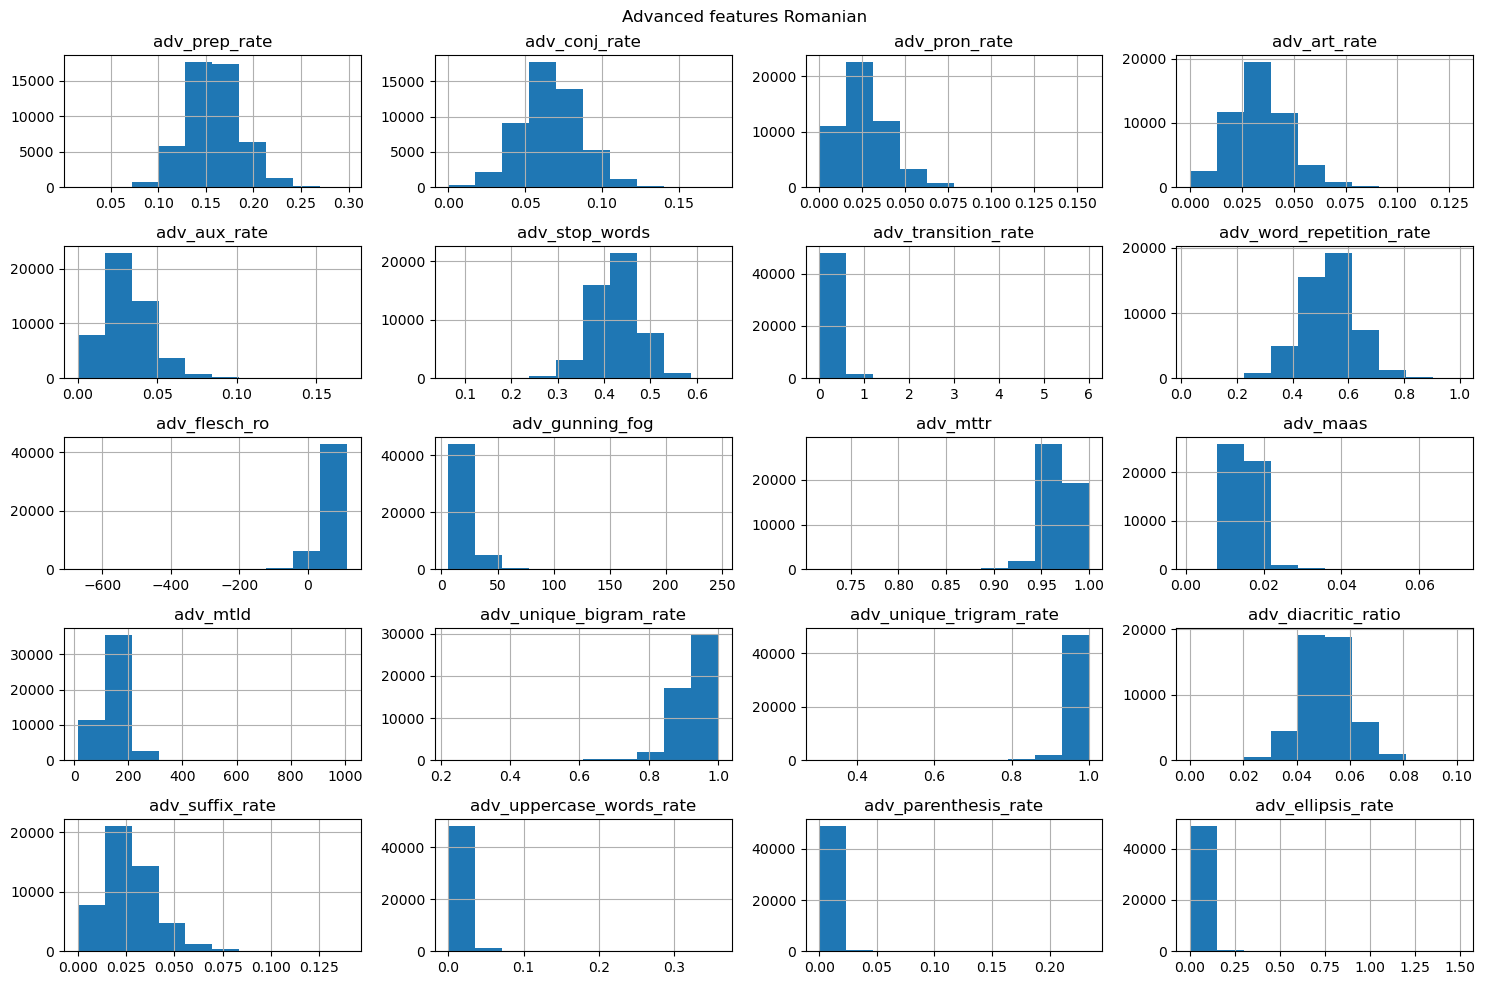

In [29]:
# X_train_adv_ro.hist(figsize=(15, 10))
# plt.tight_layout()
# plt.title("Advanced features romanian")

axes = X_train_adv_ro.hist(figsize=(15,10))

plt.suptitle("Advanced features Romanian")
plt.tight_layout()

<Axes: >

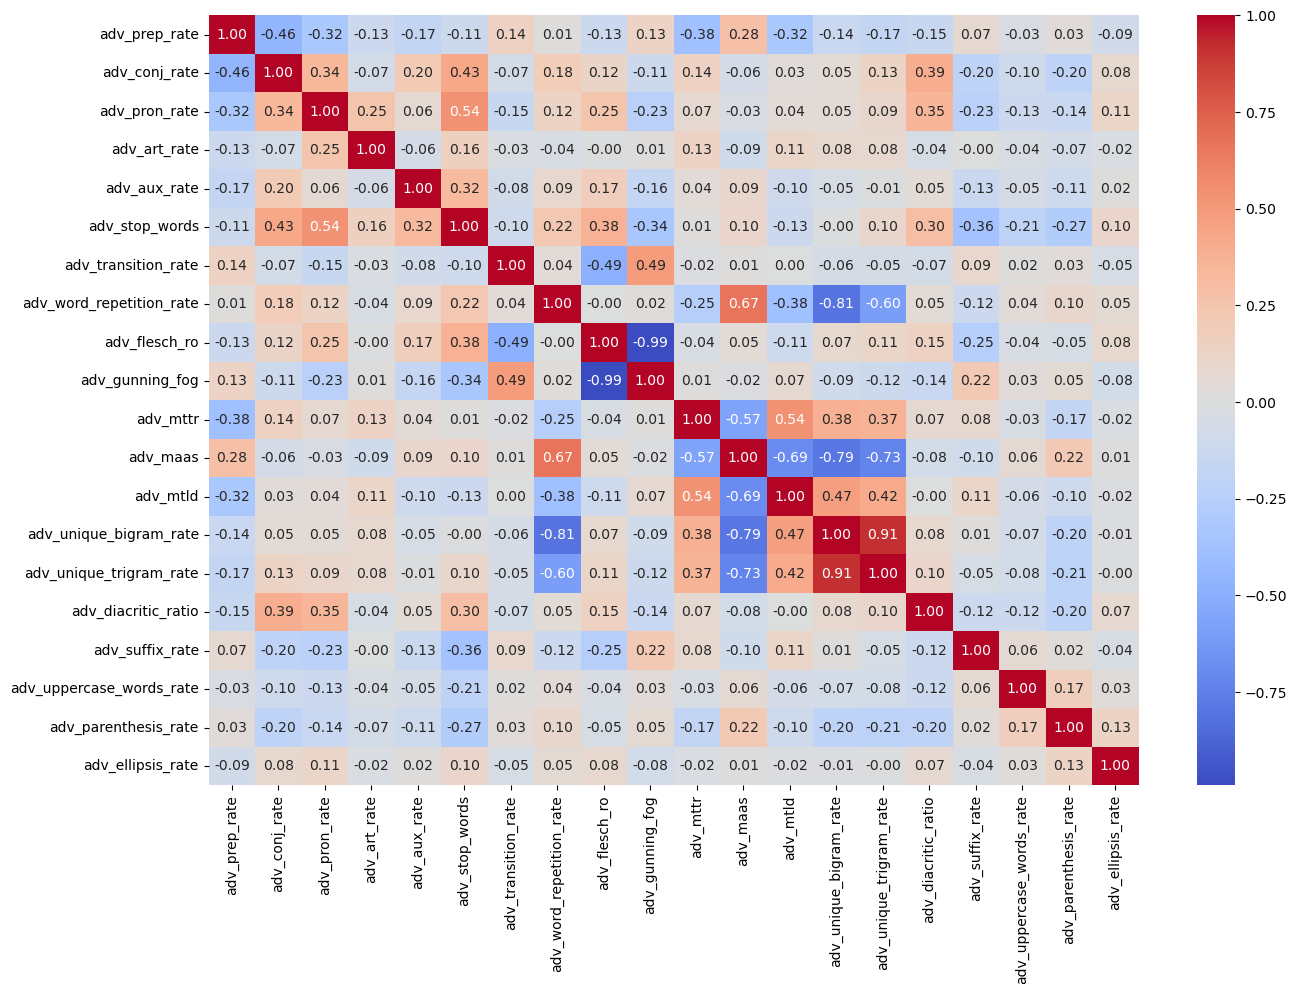

In [108]:
plt.figure(figsize=(15,10))
sns.heatmap(X_train_adv_ro.corr(), annot=True, fmt='.2f', cmap='coolwarm')

- Pastram ttr in loc de mttr 
- scoatem ellipsis, suffix rate , paranthesis
- la flesch kincaid trebuie limitat intervalul ala 

In [26]:
X_train_adv_ro["adv_flesch_ro"] = X_train_adv_ro["adv_flesch_ro"].clip(0, 100)
X_val_adv_ro["adv_flesch_ro"] = X_val_adv_ro["adv_flesch_ro"].clip(0,100)
X_test_adv_ro["adv_flesch_ro"] = X_test_adv_ro["adv_flesch_ro"].clip(0,100)
# la gunning fog am facut clip deja in functie NU E CORECT
#clip_column(X_train_adv, X_val_adv, X_test_adv, "adv_flesch_ro")
clip_column(X_train_adv_ro, X_val_adv_ro, X_test_adv_ro, "adv_mtld")
clip_column(X_train_adv_ro, X_val_adv_ro, X_test_adv_ro, "adv_gunning_fog")
# f1 cu clip 0.25
# dropam

In [110]:
# top 40 ro
X_train_adv_top40_ro["adv_flesch_ro"] = X_train_adv_top40_ro["adv_flesch_ro"].clip(0, 100)
X_val_adv_top40_ro["adv_flesch_ro"] = X_val_adv_top40_ro["adv_flesch_ro"].clip(0,100)
X_test_adv_top40_ro["adv_flesch_ro"] = X_test_adv_top40_ro["adv_flesch_ro"].clip(0,100)
# la gunning fog am facut clip deja in functie NU E CORECT
#clip_column(X_train_adv, X_val_adv, X_test_adv, "adv_flesch_ro")
clip_column(X_train_adv_top40_ro, X_val_adv_top40_ro, X_test_adv_top40_ro, "adv_mtld")
clip_column(X_train_adv_top40_ro, X_val_adv_top40_ro, X_test_adv_top40_ro, "adv_gunning_fog")

In [111]:
# top 20 mo
X_train_adv_mo["adv_flesch_ro"] = X_train_adv_mo["adv_flesch_ro"].clip(0, 100)
X_val_adv_mo["adv_flesch_ro"] = X_val_adv_mo["adv_flesch_ro"].clip(0,100)
X_test_adv_mo["adv_flesch_ro"] = X_test_adv_mo["adv_flesch_ro"].clip(0,100)
# la gunning fog am facut clip deja in functie NU E CORECT
#clip_column(X_train_adv, X_val_adv, X_test_adv, "adv_flesch_ro")
clip_column(X_train_adv_mo, X_val_adv_mo, X_test_adv_mo, "adv_mtld")
clip_column(X_train_adv_mo, X_val_adv_mo, X_test_adv_mo, "adv_gunning_fog")

In [112]:
# top 40 mo
X_train_adv_top40_mo["adv_flesch_ro"] = X_train_adv_top40_mo["adv_flesch_ro"].clip(0, 100)
X_val_adv_top40_mo["adv_flesch_ro"] = X_val_adv_top40_mo["adv_flesch_ro"].clip(0,100)
X_test_adv_top40_mo["adv_flesch_ro"] = X_test_adv_top40_mo["adv_flesch_ro"].clip(0,100)
# la gunning fog am facut clip deja in functie NU E CORECT
#clip_column(X_train_adv, X_val_adv, X_test_adv, "adv_flesch_ro")
clip_column(X_train_adv_top40_mo, X_val_adv_top40_mo, X_test_adv_top40_mo, "adv_mtld")
clip_column(X_train_adv_top40_mo, X_val_adv_top40_mo, X_test_adv_top40_mo, "adv_gunning_fog")

In [40]:
X_train_adv_ro.describe().T

,count,mean,std,min,25%,50%,75%,max
adv_prep_rate,49696.0,0.158567,0.028066,0.015228,0.140055,0.157609,0.176080,0.298643
adv_conj_rate,49696.0,0.066330,0.019364,0.000000,0.053521,0.065868,0.078710,0.175439
adv_pron_rate,49696.0,0.026512,0.014094,0.000000,0.016667,0.024845,0.034483,0.156627
adv_art_rate,49696.0,0.033657,0.013478,0.000000,0.024605,0.032913,0.041667,0.130000
adv_aux_rate,49696.0,0.031188,0.015219,0.000000,0.020833,0.029499,0.039417,0.169399
adv_stop_words,49696.0,0.425970,0.050113,0.064356,0.395349,0.425876,0.458438,0.646154
adv_transition_rate,49696.0,0.167995,0.199389,0.000000,0.000000,0.125000,0.250000,6.000000
adv_word_repetition_rate,49696.0,0.530024,0.096139,0.031746,0.468635,0.531429,0.591931,1.000000
adv_flesch_ro,49696.0,56.293563,19.701954,0.000000,46.799733,58.627126,69.414655,100.000000
adv_gunning_fog,49696.0,24.078669,6.406524,13.694532,20.210907,23.065883,26.277981,53.201018


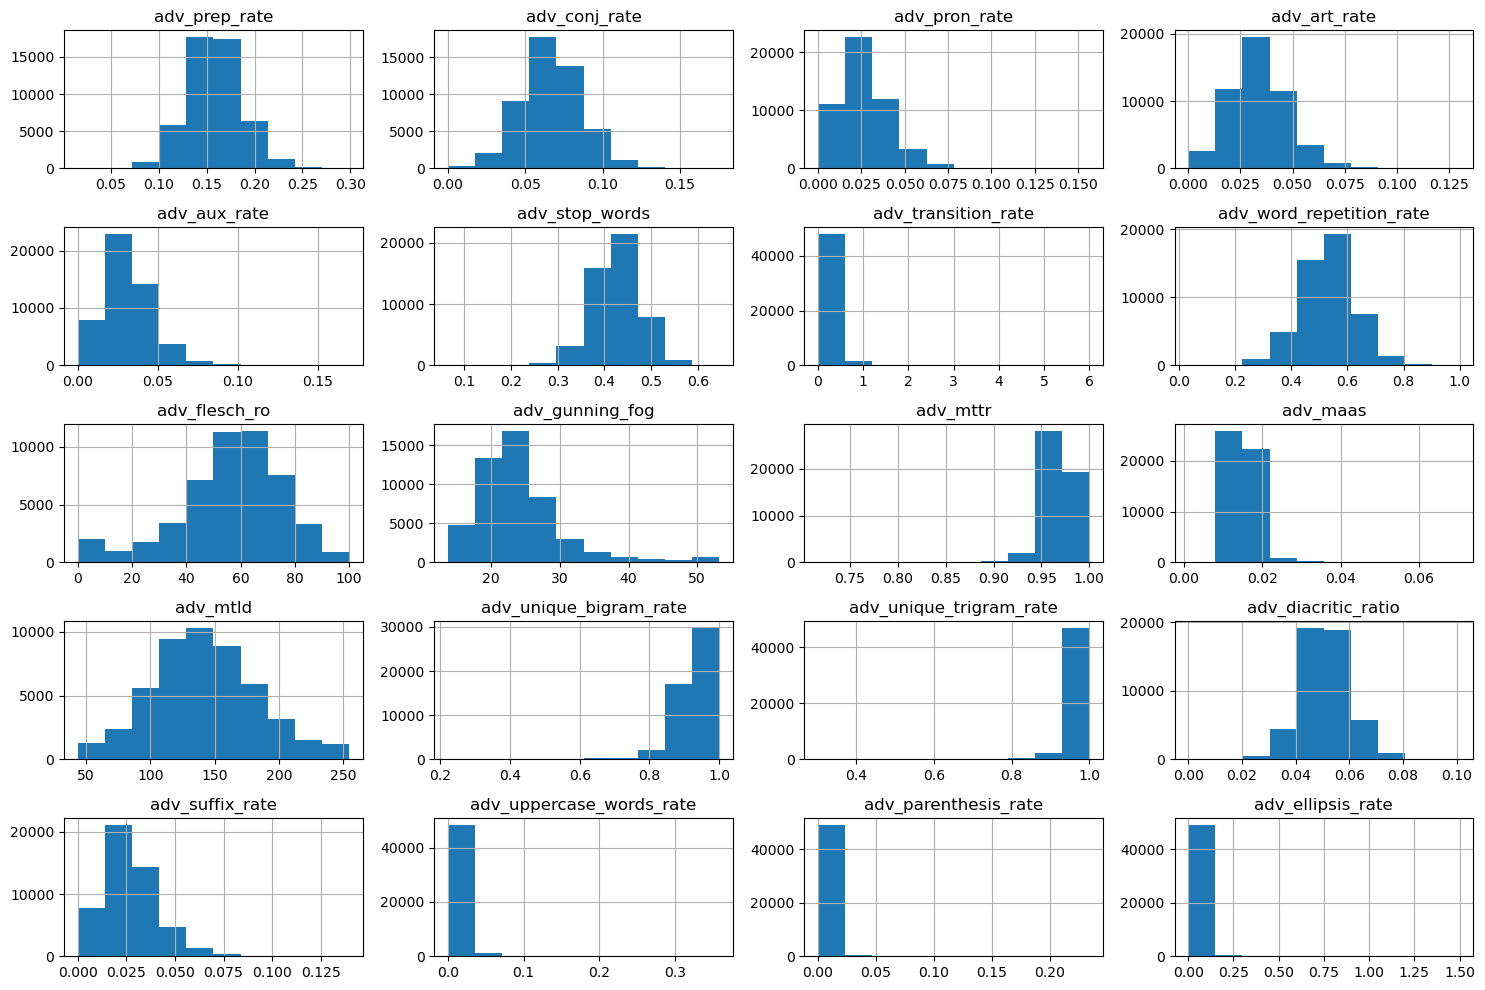

In [31]:
X_train_adv_ro.hist(figsize=(15, 10))
plt.tight_layout()

In [27]:
X_train_adv_ro.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)
X_val_adv_ro.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)
X_test_adv_ro.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)

# incerc si cu ellipsis --nah nu merge

In [116]:
# top 40 ro
X_train_adv_top40_ro.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)
X_val_adv_top40_ro.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)
X_test_adv_top40_ro.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)

In [117]:
# top 20 mo
X_train_adv_mo.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)
X_val_adv_mo.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)
X_test_adv_mo.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)

In [118]:
# top 40 mo
X_train_adv_top40_mo.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)
X_val_adv_top40_mo.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)
X_test_adv_top40_mo.drop(columns=["adv_parenthesis_rate", "adv_maas"], inplace=True)

Concatenare cu stylo

In [28]:
# concatenare
top20_ro_train = pd.concat([top20_ro_train, X_train_adv_ro], axis=1)
top20_ro_val   = pd.concat([top20_ro_val, X_val_adv_ro], axis=1)
top20_ro_test  = pd.concat([top20_ro_test, X_test_adv_ro], axis=1)

assert (top20_ro_train.index == X_train_adv_ro.index).all()
assert (top20_ro_val.index == X_val_adv_ro.index).all()
assert (top20_ro_test.index == X_test_adv_ro.index).all()
# daca assertul da bine scriem in fisiere

In [120]:
# top 40 ro
top40_ro_train = pd.concat([top40_ro_train, X_train_adv_top40_ro], axis=1)
top40_ro_val   = pd.concat([top40_ro_val, X_val_adv_top40_ro], axis=1)
top40_ro_test  = pd.concat([top40_ro_test, X_test_adv_top40_ro], axis=1)

assert (top40_ro_train.index == X_train_adv_top40_ro.index).all()
assert (top40_ro_val.index == X_val_adv_top40_ro.index).all()
assert (top40_ro_test.index == X_test_adv_top40_ro.index).all()

In [121]:
# top 20 mo
top20_train_mo_stratified = pd.concat([top20_train_mo_stratified, X_train_adv_mo], axis=1)
top20_val_mo_stratified = pd.concat([top20_val_mo_stratified, X_val_adv_mo], axis=1)
top20_test_mo_stratified = pd.concat([top20_test_mo_stratified, X_test_adv_mo], axis=1)
 
assert (top20_train_mo_stratified.index == X_train_adv_mo.index).all()
assert (top20_val_mo_stratified.index == X_val_adv_mo.index).all()
assert (top20_test_mo_stratified.index == X_test_adv_mo.index).all()

In [122]:
# top 40 mo
top40_train_mo_stratified = pd.concat([top40_train_mo_stratified, X_train_adv_top40_mo], axis=1)
top40_val_mo_stratified = pd.concat([top40_val_mo_stratified, X_val_adv_top40_mo], axis=1)
top40_test_mo_stratified = pd.concat([top40_test_mo_stratified, X_test_adv_top40_mo], axis=1)

assert (top40_train_mo_stratified.index == X_train_adv_top40_mo.index).all()
assert (top40_val_mo_stratified.index == X_val_adv_top40_mo.index).all()
assert (top40_test_mo_stratified.index == X_test_adv_top40_mo.index).all()

In [123]:
save_final_stilo_tops(top20_ro_train, "final_stilo/top20_ro_train.csv")
save_final_stilo_tops(top20_ro_val, "final_stilo/top20_ro_val.csv")
save_final_stilo_tops(top20_ro_test, "final_stilo/top20_ro_test.csv")

save_final_stilo_tops(top40_ro_train, "final_stilo/top40_ro_train.csv")
save_final_stilo_tops(top40_ro_val, "final_stilo/top40_ro_val.csv")
save_final_stilo_tops(top40_ro_test, "final_stilo/top40_ro_test.csv")

save_final_stilo_tops(top20_train_mo_stratified, "final_stilo/top20_mo_train.csv")
save_final_stilo_tops(top20_val_mo_stratified, "final_stilo/top20_mo_val.csv")
save_final_stilo_tops(top20_test_mo_stratified, "final_stilo/top20_mo_test.csv")

save_final_stilo_tops(top40_train_mo_stratified, "final_stilo/top40_mo_train.csv")
save_final_stilo_tops(top40_val_mo_stratified, "final_stilo/top40_mo_val.csv")
save_final_stilo_tops(top40_test_mo_stratified, "final_stilo/top40_mo_test.csv")

### Preprocesare
- definesti ce coloane folosesti la train (in caz de summary, sau title, sau prop idk)
- normalizam cu standard scaler (stilo)

In [29]:
print(top20_ro_train.shape)
print(top20_mo_train.shape)

print(top20_ro_test.shape)
print(top20_mo_test.shape)

print(top20_ro_val.shape)
print(top20_mo_val.shape)

print(top40_ro_train.shape)
print(top40_mo_train.shape)

print(top40_ro_test.shape)
print(top40_mo_test.shape)

print(top40_ro_val.shape)
print(top40_mo_val.shape)

# inca nu am facut moldova cu advanced features no worries bagam pe gpu si testam pe romania  mai intai

(49696, 53)
(47065, 35)
(1319, 53)
(1049, 35)
(1340, 53)
(1051, 35)
(66991, 35)
(56657, 35)
(1761, 35)
(1173, 35)
(1790, 35)
(1189, 35)


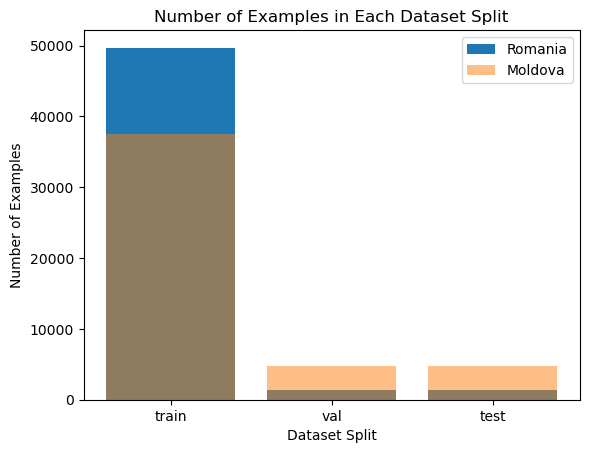

In [35]:
examples_ro = [49696, 1319, 1340]
examples_mo = [37534, 4692, 4692]

plt.bar(['train', 'val', 'test'], examples_ro, label='Romania')
plt.bar(['train', 'val', 'test'], examples_mo, label='Moldova', alpha=0.5)
plt.xlabel('Dataset Split')
plt.ylabel('Number of Examples')
plt.title('Number of Examples in Each Dataset Split')
plt.legend()

In [34]:
top20_ro_train.columns

Index(['text', 'summary', 'title', 'keywords', 'dialect', 'topics', 'url',
       'author', 'stylo_word_count', 'stylo_char_count',
       'stylo_avg_word_length', 'stylo_std_word_length',
       'stylo_sentence_count', 'stylo_std_sentence_length',
       'stylo_avg_sentence_length', 'stylo_ttr', 'stylo_hapax_rate',
       'stylo_punctuation_rate', 'stylo_question_rate',
       'stylo_exclamation_rate', 'stylo_uppercase_ratio', 'stylo_digit_ratio',
       'stylo_comma_rate', 'stylo_semicolon_rate', 'stylo_dash_rate',
       'stylo_quote_rate', 'stylo_lexical_diversity', 'stylo_noun_ratio',
       'stylo_verb_ratio', 'stylo_adj_ratio', 'stylo_adv_ratio',
       'stylo_pron_ratio', 'stylo_det_ratio', 'stylo_aux_ratio',
       'stylo_avg_depth_tree', 'adv_prep_rate', 'adv_conj_rate',
       'adv_pron_rate', 'adv_art_rate', 'adv_aux_rate', 'adv_stop_words',
       'adv_transition_rate', 'adv_word_repetition_rate', 'adv_flesch_ro',
       'adv_gunning_fog', 'adv_mttr', 'adv_mtld', 'adv_uniq

In [30]:
features_col_stilo = [
    #'stylo_word_count',
    # 'stylo_avg_depth_tree',
    'stylo_char_count',
    'stylo_avg_word_length',
    'stylo_std_word_length',
    'stylo_avg_sentence_length',
    'stylo_std_sentence_length',
    'stylo_sentence_count',
    'stylo_ttr',
    'stylo_hapax_rate',
    'stylo_punctuation_rate',
    'stylo_question_rate',
    'stylo_exclamation_rate',
    'stylo_quote_rate',
    'stylo_lexical_diversity',
    'stylo_aux_ratio',
    #'stylo_noun_ratio', # corelatie 0.73 cu lexical diveristy nu are sens, am decomentat sa am ce arata
    'stylo_verb_ratio',
    'stylo_adj_ratio',
    'stylo_adv_ratio',
    "adv_prep_rate", 
    "adv_conj_rate", 
    "adv_pron_rate",
    "adv_art_rate",
    #"adv_aux_rate", # am si stylo aux ratio?
    "adv_transition_rate",
    "adv_word_repetition_rate", 
    "adv_flesch_ro",
    "adv_unique_bigram_rate",
    "adv_diacritic_ratio",
    "adv_suffix_rate",
    "adv_mttr",
    #"adv_maas",
    "adv_mtld",
    "adv_gunning_fog",
    "adv_uppercase_words_rate",
    "adv_unique_trigram_rate",
    # "adv_parenthesis_rate",
    #"adv_ellipsis_rate"
]



## Train test Romania STILOMETRIE + SHALLOW MODELS

In [31]:
x_train_top20_ro_stilo = top20_ro_train[features_col_stilo]
x_val_top20_ro_stilo = top20_ro_val[features_col_stilo]
x_test_top20_ro_stilo = top20_ro_test[features_col_stilo]

y_train_top20_ro_stilo = top20_ro_train['author']
y_val_top20_ro_stilo = top20_ro_val['author']
y_test_top20_ro_stilo = top20_ro_test['author']

# x_train_top20_mo_stilo = top20_train_mo_stratified[features_col_stilo]
# x_val_top20_mo_stilo = top20_val_mo_stratified[features_col_stilo]
# x_test_top20_mo_stilo = top20_test_mo_stratified[features_col_stilo]

# y_train_top20_mo_stilo = top20_train_mo_stratified['author']
# y_val_top20_mo_stilo = top20_val_mo_stratified['author']
# y_test_top20_mo_stilo = top20_test_mo_stratified['author']


In [43]:
# Putem folosi Standard sau Robust scaler 
# depinde de outliers
# ne uitam la diferenta dintre quantila 75% si max 
# daca max e mult mai mare ca 75% am outliers 
x_train_top20_ro_stilo.describe().T

,count,mean,std,min,25%,50%,75%,max
stylo_avg_depth_tree,49696.0,2.945747,0.474768,1.375000,2.630137,2.907020,3.209488,8.692201
stylo_char_count,49696.0,2132.519780,1981.958588,272.000000,1197.000000,1727.000000,2448.000000,44984.000000
stylo_avg_word_length,49696.0,5.026633,0.386310,3.166667,4.778059,5.030043,5.267241,7.178862
stylo_std_word_length,49696.0,3.004292,0.229362,1.897479,2.859315,3.005329,3.148799,6.791893
stylo_avg_sentence_length,49696.0,23.318730,7.115077,2.852273,18.809524,22.750000,27.166667,375.000000
stylo_std_sentence_length,49696.0,11.059884,4.970875,0.000000,8.380654,10.456691,12.830504,317.894252
stylo_sentence_count,49696.0,15.618078,14.822070,1.000000,8.000000,12.000000,18.000000,357.000000
stylo_ttr,49696.0,0.613811,0.085913,0.134572,0.559727,0.615385,0.670051,0.984127
stylo_hapax_rate,49696.0,0.469976,0.096139,0.000000,0.408069,0.468571,0.531365,0.968254
stylo_punctuation_rate,49696.0,0.012020,0.003793,0.000000,0.009610,0.011588,0.013864,0.075810


Text(0.5, 1.0, 'Distribution of all stilometryc features')

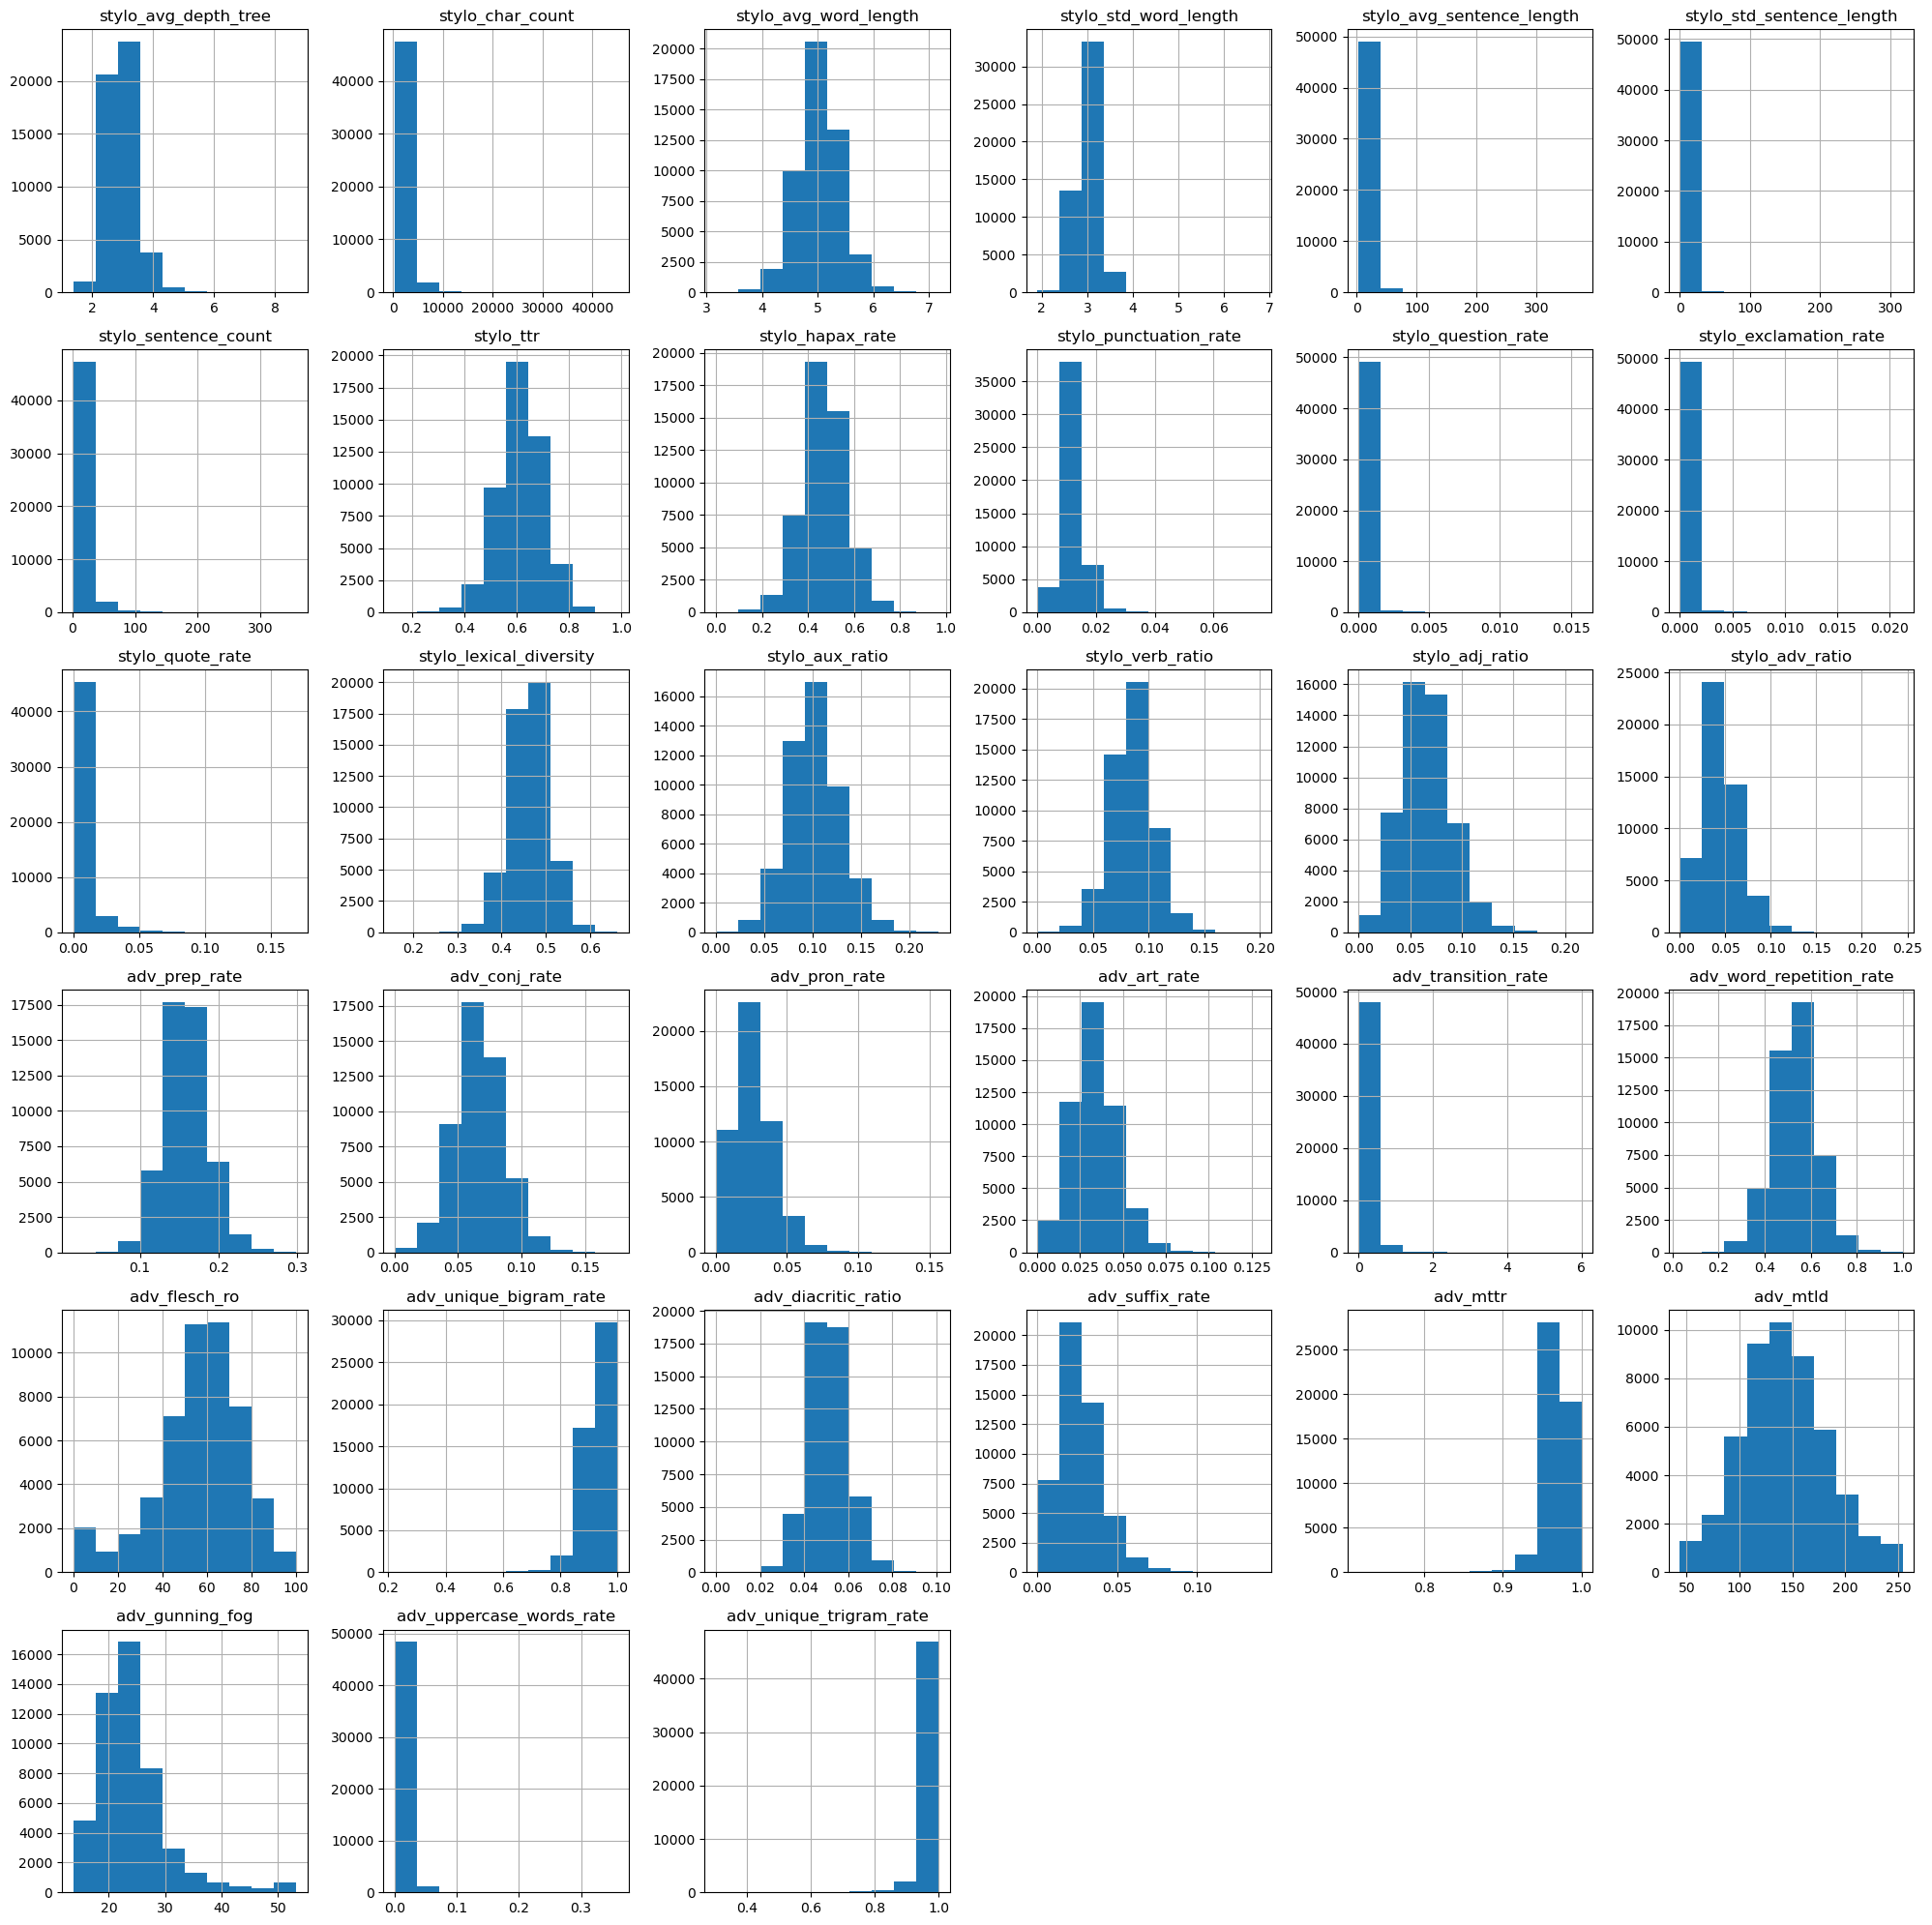

In [44]:
x_train_top20_ro_stilo.hist(figsize=(20,20))
plt.tight_layout()
plt.title("Distribution of all stilometryc features")

<Axes: >

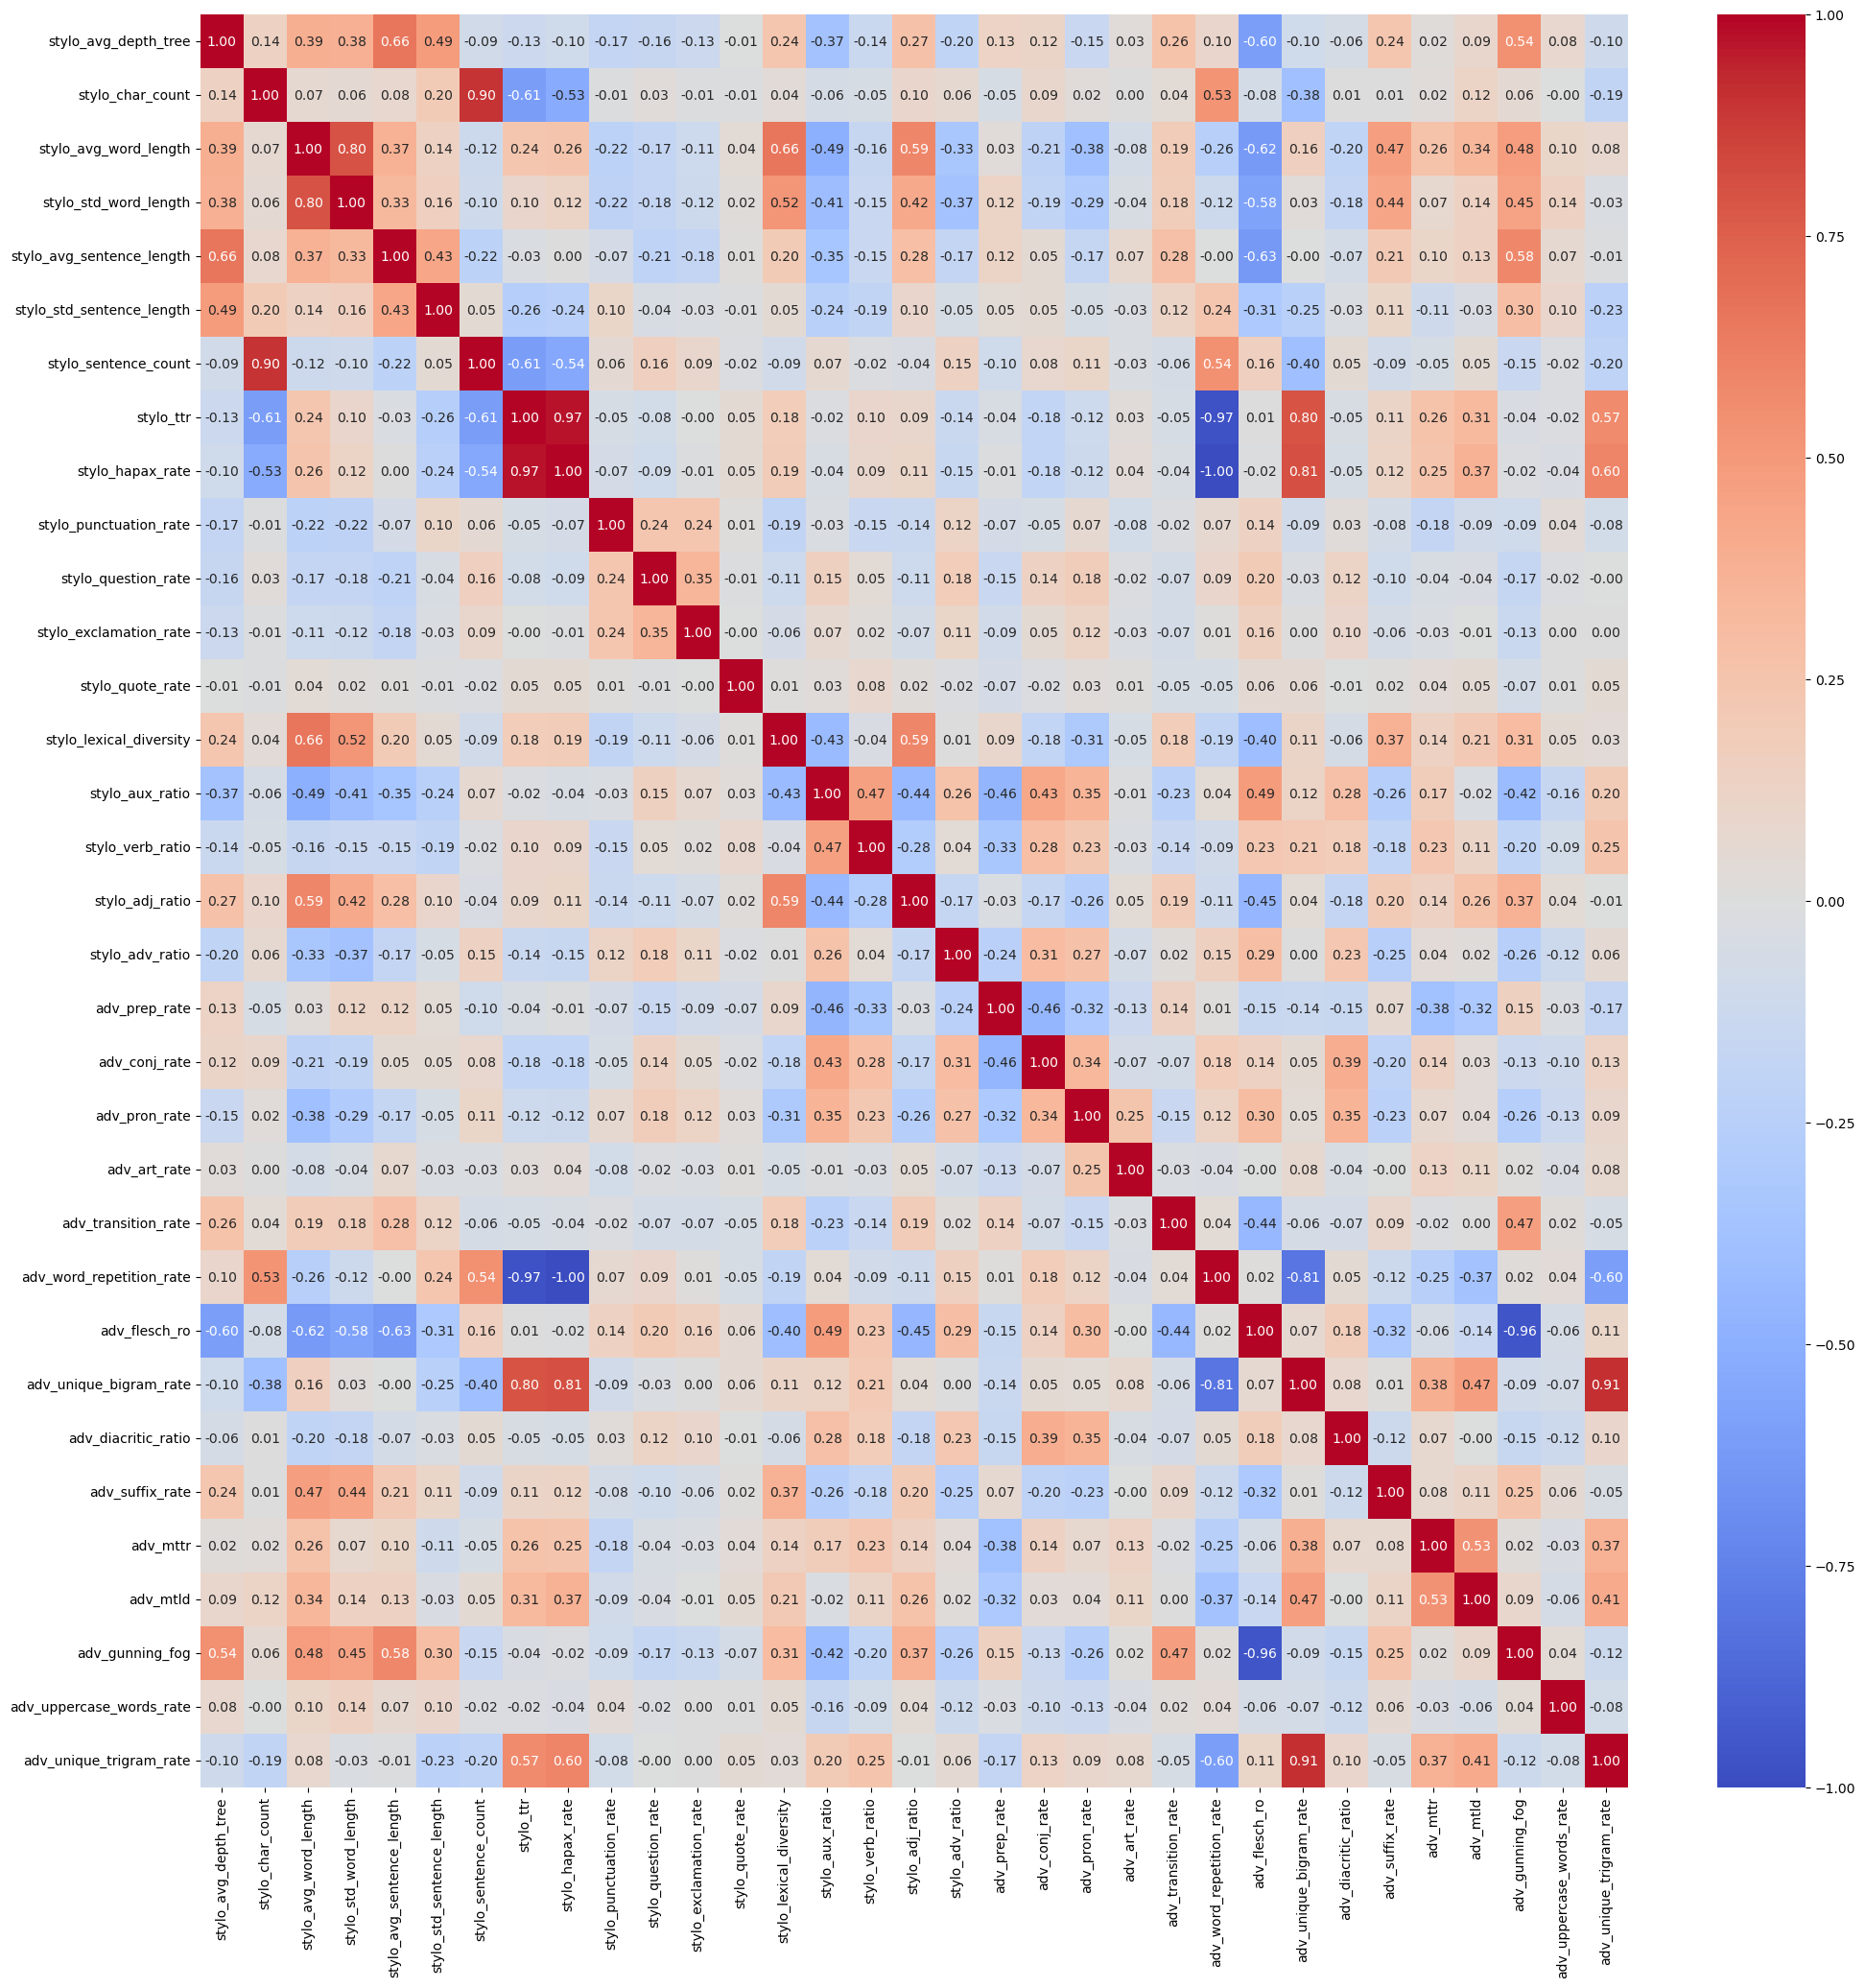

In [45]:
plt.figure(figsize=(24,24))
sns.heatmap(x_train_top20_ro_stilo.corr(), annot=True, fmt='.2f', cmap='coolwarm')

In [32]:
# definim mai inatai Standard Scaler
# astea vor intra in model!
scaler_standard = StandardScaler()

x_train_top20_ro_stilo_std_scaled = scaler_standard.fit_transform(x_train_top20_ro_stilo)
x_val_top20_ro_stilo_std_scaled = scaler_standard.transform(x_val_top20_ro_stilo)
x_test_top20_ro_stilo_std_scaled = scaler_standard.transform(x_test_top20_ro_stilo)


# x_train_top20_mo_stilo_std_scaled = scaler_standard.fit_transform(x_train_top20_mo_stilo)
# x_val_top20_mo_stilo_std_scaled = scaler_standard.transform(x_val_top20_mo_stilo)
# x_test_top20_mo_stilo_std_scaled = scaler_standard.transform(x_test_top20_mo_stilo)

### N-grams
- avand prea putine atribute stilometrice , va trebui sa ne ajutam de n-grams
- worst case va trebui sa fac fusion cu pos-n-grams, char n-grams, word n-grams
- toate astea tin de tf -df 

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

vectorizer_char = TfidfVectorizer(
    analyzer='char_wb',   # char_wb e mai bun decat char pentru texte
    ngram_range=(3, 4),
    max_features=20000,
    sublinear_tf=True     # aplica log la frecvente
)

X_train_char = vectorizer_char.fit_transform(top20_ro_train['text'])
X_val_char   = vectorizer_char.transform(top20_ro_val['text'])



In [34]:
print(f"X_train_char shape: {X_train_char.shape}")
print(f"X_val_char shape: {X_val_char.shape}")

X_train_char shape: (49696, 20000)
X_val_char shape: (1340, 20000)


In [35]:
# cum fac sa printez toate numele de features din vectorizer?
feature_names_char = vectorizer_char.get_feature_names_out()
print(f"Numar de features char: {len(feature_names_char)}")
print("Primele 20 de features char:", feature_names_char[:20])

Numar de features char: 20000
Primele 20 de features char: [' "a' ' "a ' ' "ac' ' "am' ' "b' ' "c' ' "ce' ' "co' ' "d' ' "da' ' "de'
 ' "di' ' "e' ' "es' ' "f' ' "i' ' "in' ' "l' ' "m' ' "n']


In [36]:
for f in vectorizer_char.get_feature_names_out()[:20]:
    print(repr(f), len(f))

' "a' 3
' "a ' 4
' "ac' 4
' "am' 4
' "b' 3
' "c' 3
' "ce' 4
' "co' 4
' "d' 3
' "da' 4
' "de' 4
' "di' 4
' "e' 3
' "es' 4
' "f' 3
' "i' 3
' "in' 4
' "l' 3
' "m' 3
' "n' 3


In [37]:
print(len(features_col_stilo))

32


In [ ]:
y_train = top20_ro_train['author']
y_val   = top20_ro_val['author']

lr = LogisticRegression(max_iter=1000, class_weight='balanced', C=5)
lr.fit(X_train_char, y_train)

y_pred = lr.predict(X_val_char)
print(f"Char n-grams F1 macro: {f1_score(y_val, y_pred, average='macro'):.3f}")
# ngram 2-4 , 12 minute F1 0.48 , max features 100 000
# ngram 3-5 max features = 5000 F1 = 0.419  10 minute
# ngram 2-5 max features 1000 F1 =0.31 5 minute
# ngram 3-5 max feature 10000 F1 macro: 0.433 12 minute
# ngram 3-4 max features 20000 F1 macro: 0.492 10 minute 

In [ ]:
from scipy.sparse import hstack

# Combina caracteristicile TF-IDF cu cele stilometrice
X_train_combined = hstack([X_train_char, x_train_top20_ro_stilo_std_scaled])
X_val_combined = hstack([X_val_char, x_val_top20_ro_stilo_std_scaled])  # sau validation daca ai

In [ ]:
print(f"Combined X_train shape: {X_train_combined.shape}")
print(f"Combined X_val shape: {X_val_combined.shape}")

In [ ]:


# Antreneaza pe caracteristici combinate
clf_combined = LogisticRegression(max_iter=1000, class_weight='balanced', C=5)
clf_combined.fit(X_train_combined, y_train)

# Predictie
y_pred_combined = clf_combined.predict(X_val_combined)

print(f"Combined F1 macro: {f1_score(y_val, y_pred_combined, average='macro'):.3f}")
print(classification_report(y_val, y_pred_combined))
# 24 de minute 0.494 sau ceva
# asta cu 0.495 e cu avg depth tree uau

Combined F1 macro: 0.495
                    precision    recall  f1-score   support

    Adrian Dumitru       0.54      0.63      0.59        87
Alexandra Andronie       0.41      0.46      0.43        50
  Alexandru Costea       0.46      0.45      0.46        96
  Alexandru Toader       0.38      0.44      0.41        36
     Alina Manaila       0.56      0.69      0.62        39
     Alina Popescu       0.24      0.24      0.24        49
   Andrada Giubega       0.83      0.92      0.88        38
    Andreea Tobias       0.52      0.58      0.55        19
    Bogdan Pacurar       0.48      0.33      0.39       103
   Daniela Chihaia       0.37      0.48      0.42        42
     Diana Nechita       0.84      0.70      0.76       108
  Georgiana Marina       0.68      0.55      0.61       122
       Ioana Coman       0.25      0.24      0.24        68
       Liviu Cojan       0.39      0.31      0.35       112
    Luana Pavaluca       0.59      0.60      0.59        92
       Marco B

In [ ]:
# Antreneaza pe caracteristici combinate
clf_combined_svc = LinearSVC(max_iter=1000, class_weight='balanced', C=5)
clf_combined_svc.fit(X_train_combined, y_train)

# Predictie
y_pred_combined_svc = clf_combined_svc.predict(X_val_combined)

print(f"Combined F1 macro: {f1_score(y_val, y_pred_combined_svc, average='macro'):.3f}")
print(classification_report(y_val, y_pred_combined_svc))
# 62 minute pt F1 0.473 ....

Combined F1 macro: 0.473
                    precision    recall  f1-score   support

    Adrian Dumitru       0.53      0.56      0.55        87
Alexandra Andronie       0.37      0.50      0.43        50
  Alexandru Costea       0.45      0.47      0.46        96
  Alexandru Toader       0.38      0.42      0.40        36
     Alina Manaila       0.56      0.62      0.59        39
     Alina Popescu       0.27      0.22      0.24        49
   Andrada Giubega       0.83      0.92      0.88        38
    Andreea Tobias       0.48      0.58      0.52        19
    Bogdan Pacurar       0.35      0.32      0.33       103
   Daniela Chihaia       0.40      0.45      0.43        42
     Diana Nechita       0.76      0.66      0.71       108
  Georgiana Marina       0.59      0.49      0.54       122
       Ioana Coman       0.17      0.19      0.18        68
       Liviu Cojan       0.33      0.34      0.33       112
    Luana Pavaluca       0.58      0.48      0.52        92
       Marco B

### Logistic Regression

In [130]:
# ROMANIA
clf = LogisticRegression(max_iter=1000, class_weight='balanced')
clf.fit(x_train_top20_ro_stilo_std_scaled, y_train_top20_ro_stilo)
y_pred_ro_stilo_top20 = clf.predict(x_test_top20_ro_stilo_std_scaled)

print(classification_report(y_test_top20_ro_stilo, y_pred_ro_stilo_top20))


                    precision    recall  f1-score   support

    Adrian Dumitru       0.20      0.26      0.22        77
Alexandra Andronie       0.19      0.24      0.21        46
  Alexandru Costea       0.25      0.03      0.05       100
  Alexandru Toader       0.11      0.23      0.15        30
     Alina Manaila       0.31      0.38      0.34        42
     Alina Popescu       0.06      0.04      0.05        48
   Andrada Giubega       0.48      0.56      0.52        41
    Andreea Tobias       0.41      0.76      0.53        29
    Bogdan Pacurar       0.11      0.02      0.04        96
   Daniela Chihaia       0.17      0.49      0.25        39
     Diana Nechita       0.66      0.52      0.58       110
  Georgiana Marina       0.62      0.28      0.38       127
       Ioana Coman       0.08      0.02      0.03        53
       Liviu Cojan       0.31      0.16      0.21       128
    Luana Pavaluca       0.36      0.42      0.39       102
       Marco Badea       0.12      0.36

In [59]:
from sklearn.metrics import f1_score

for C in [0.01, 0.1, 1, 10, 100, 1000]:
    lr = LogisticRegression(C=C, max_iter=1000, class_weight='balanced')
    lr.fit(x_train_top20_ro_stilo_std_scaled, y_train_top20_ro_stilo)
    y_pred = lr.predict(x_val_top20_ro_stilo_std_scaled)
    f1 = f1_score(y_val_top20_ro_stilo, y_pred, average='macro')
    print(f"C={C}: F1={f1:.3f}")

C=0.01: F1=0.224
C=0.1: F1=0.234
C=1: F1=0.240
C=10: F1=0.238
C=100: F1=0.235
C=1000: F1=0.236


### Linear SVC

In [131]:
clasifier_svc = LinearSVC(class_weight='balanced')
clasifier_svc.fit(x_train_top20_ro_stilo_std_scaled, y_train_top20_ro_stilo)
y_pred_ro_stilo_top20 = clasifier_svc.predict(x_test_top20_ro_stilo_std_scaled)

print(classification_report(y_test_top20_ro_stilo, y_pred_ro_stilo_top20))

                    precision    recall  f1-score   support

    Adrian Dumitru       0.18      0.26      0.22        77
Alexandra Andronie       0.20      0.20      0.20        46
  Alexandru Costea       0.20      0.01      0.02       100
  Alexandru Toader       0.08      0.13      0.10        30
     Alina Manaila       0.28      0.36      0.32        42
     Alina Popescu       0.00      0.00      0.00        48
   Andrada Giubega       0.43      0.66      0.52        41
    Andreea Tobias       0.26      0.79      0.39        29
    Bogdan Pacurar       0.20      0.01      0.02        96
   Daniela Chihaia       0.17      0.46      0.24        39
     Diana Nechita       0.55      0.65      0.59       110
  Georgiana Marina       0.53      0.33      0.41       127
       Ioana Coman       0.00      0.00      0.00        53
       Liviu Cojan       0.28      0.16      0.21       128
    Luana Pavaluca       0.33      0.38      0.36       102
       Marco Badea       0.12      0.39

/home/daria/miniconda3/envs/ia-labs-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/daria/miniconda3/envs/ia-labs-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/daria/miniconda3/envs/ia-labs-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

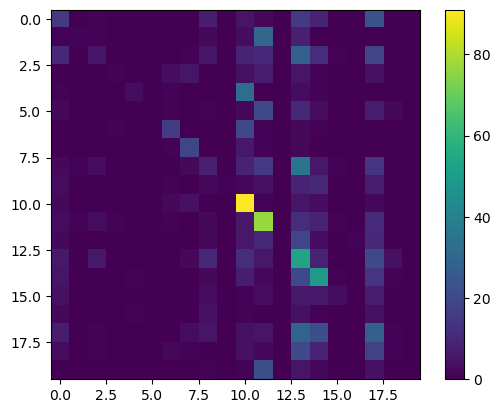

In [63]:
cm = confusion_matrix(y_test_top20_ro_stilo, y_pred_ro_stilo_top20)

plt.imshow(cm)
plt.colorbar()

In [133]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=1000,
    max_depth=10,
    n_jobs=-1
)

rf.fit(x_train_top20_ro_stilo, y_train_top20_ro_stilo)
rf.fit(x_train_top20_ro_stilo_std_scaled, y_train_top20_ro_stilo)
y_pred_rf = rf.predict(x_val_top20_ro_stilo_std_scaled)
print(f"RF F1 macro: {f1_score(y_val_top20_ro_stilo, y_pred_rf, average='macro'):.3f}")

RF F1 macro: 0.190


In [44]:
print(top20_ro_train['author'].value_counts())

author
Liviu Cojan           4719
Monica Bonea          4137
Georgiana Marina      4043
Bogdan Pacurar        3873
Diana Nechita         3765
Alexandru Costea      3390
Luana Pavaluca        3258
Adrian Dumitru        2673
Ioana Coman           2471
Robert Kiss           2400
Alexandra Andronie    2147
Alina Popescu         1832
Daniela Chihaia       1655
Andrada Giubega       1621
Vlad Mironescu        1465
Alina Manaila         1450
Alexandru Toader      1292
Marco Badea           1223
Andreea Tobias        1167
Mihnea Lazar          1115
Name: count, dtype: int64


In [47]:
print(x_train_top20_ro_stilo.describe())
# cauta valori infinite sau foarte mari
print((x_train_top20_ro_stilo == float('inf')).sum())
print(x_train_top20_ro_stilo.isna().sum())

       stylo_avg_word_length  stylo_std_word_length  \
count           49631.000000           49631.000000   
mean                5.026541               3.004248   
std                 0.386439               0.229430   
min                 3.166667               1.897479   
25%                 4.777778               2.859231   
50%                 5.029915               3.005297   
75%                 5.267274               3.148796   
max                 7.178862               6.791893   

       stylo_avg_sentence_length  stylo_std_sentence_length     stylo_ttr  \
count               49631.000000               49631.000000  49631.000000   
mean                   23.317592                  11.058867      0.613907   
std                     7.116283                   4.973045      0.085872   
min                     2.852273                   0.000000      0.134572   
25%                    18.801786                   8.379713      0.559846   
50%                    22.750000          

In [48]:
autori_train = set(top20_ro_train['author'].unique())
autori_val = set(top20_ro_val['author'].unique())
print(f"In val dar nu in train: {autori_val - autori_train}")

In val dar nu in train: set()


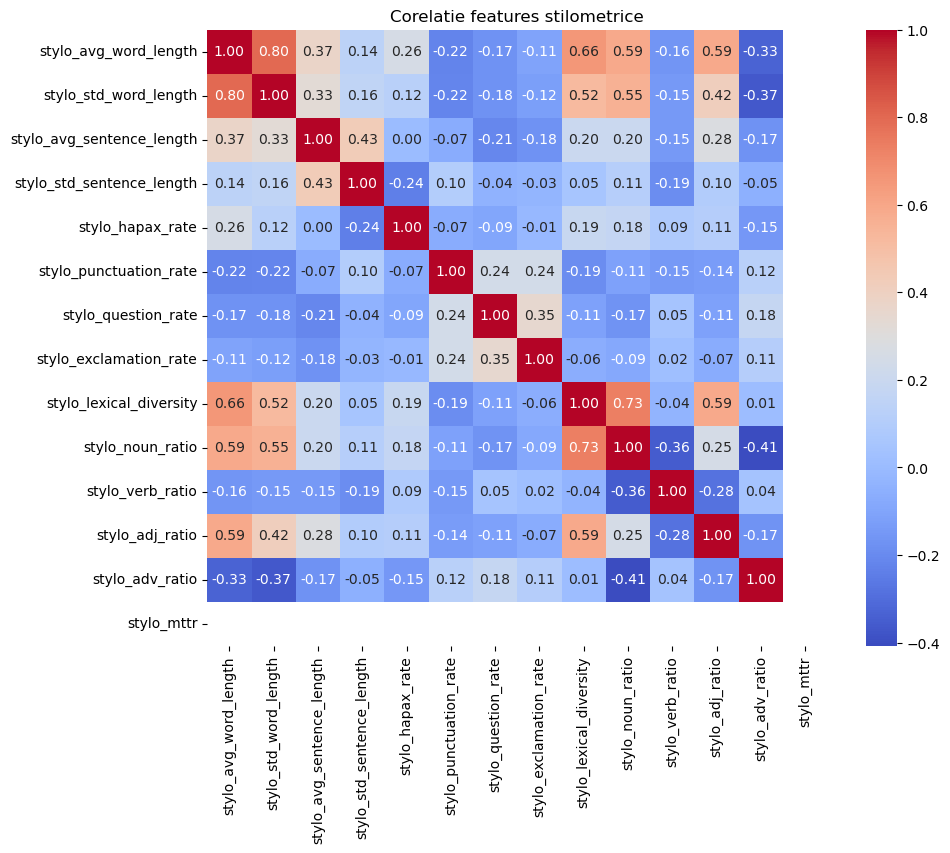

In [45]:
import seaborn as sns

corr = x_train_top20_ro_stilo.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Corelatie features stilometrice')
plt.show()